<a href="https://colab.research.google.com/github/FrankEHA/INGENIERIA_DEL_CONOCIMIENTO/blob/main/Feature_Extraction_TL_Ships_Rice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Transfer Learning — Feature Extraction aplicado a problemas reales

**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps
**Integrantes:** _______________________________________________

---

### 🎯 Objetivos de este notebook
1. **Aplicar** Feature Extraction con backbones pre-entrenados en ImageNet a dos problemas reales
2. **Resolver** una clasificación **binaria desbalanceada** (detección de barcos en imágenes satelitales)
3. **Resolver** una clasificación **multiclase** (identificación de variedades de arroz)
4. **Comparar** 4 backbones y **visualizar** los features transferidos con t-SNE

### 📚 Estructura
| Ejemplo | Nivel | Dataset | Modelo Base | Enfoque |
|---------|-------|---------|-------------|---------|
| 1 | 🟢 Básico | Ships in Satellite Imagery (barco / no barco) | MobileNetV2 | Binaria + desbalance + escaneo de escena completa |
| 2 | 🟡 Intermedio | Rice Image Dataset (5 variedades) | EfficientNetB0 | EDA + Augmentation + Métricas + Feature maps |
| 3 | 🔴 Avanzado | Rice Image Dataset | Comparación 4 backbones | Benchmark + t-SNE |

### 🌎 Problemáticas abordadas
- **Ejemplo 1 — Vigilancia marítima:** revisar a mano miles de km² de imágenes satelitales para encontrar embarcaciones (pesca ilegal, control de puertos, rescate) es inviable. Un clasificador que detecte barcos permite **escanear escenas completas automáticamente**.
- **Ejemplo 2 — Control de calidad agroindustrial:** distinguir variedades de arroz a simple vista es lento y subjetivo; la mezcla de variedades es un problema de calidad y de fraude comercial. Un modelo de visión puede **clasificar granos de forma automática y consistente**.

## ⚙️ Configuración del Entorno

Verificamos GPU disponible e instalamos dependencias.

In [1]:
# Verificar GPU
import subprocess
gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                          '--format=csv,noheader'], capture_output=True, text=True)
print("🖥️ GPU detectada:", gpu_info.stdout.strip() or "⚠️ No hay GPU — activa en Runtime > Change runtime type > T4 GPU")

🖥️ GPU detectada: Tesla T4, 15360 MiB


In [2]:
!pip install -q kagglehub

import os, glob, re, time
import kagglehub
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score)
import warnings
warnings.filterwarnings('ignore')

# Configuración global
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU disponible: {tf.config.list_physical_devices('GPU')}")

✅ TensorFlow 2.21.0
✅ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


> 🔑 **Sobre Kaggle:** `kagglehub.dataset_download(...)` descarga datasets públicos. Si Colab te pide credenciales, ejecuta `kagglehub.login()` y pega tu usuario y API key (Kaggle → Settings → API → *Create New Token*).
>
> Usamos `dataset_download` (descarga la carpeta completa) en lugar de `load_dataset(KaggleDatasetAdapter.PANDAS, ...)`, porque ese adaptador es para archivos **tabulares** (CSV, JSON) y aquí trabajamos con **imágenes**.

---
# 📖 Fundamentos de Transfer Learning

## ¿Qué es Transfer Learning?

> **Transferir conocimiento** de una tarea donde hay abundancia de datos (ej. ImageNet: 14M imágenes, 1000 clases) a una tarea donde tenemos pocos datos (nuestro problema específico).

### ¿Por qué funciona en CNNs?
Las capas de una CNN entrenada en ImageNet aprenden features progresivamente más abstractos:

```
Capa 1-3:  Bordes, gradientes, colores      → UNIVERSALES (útiles para cualquier imagen)
Capa 4-7:  Texturas, patrones repetitivos   → SEMI-UNIVERSALES
Capa 8-12: Partes de objetos (ojos, ruedas) → SEMI-ESPECÍFICOS
Capa 13+:  Objetos completos (gato, auto)   → ESPECÍFICOS de ImageNet
```

Nuestros dos problemas **no se parecen a ImageNet** (vistas satelitales y granos de arroz sobre fondo negro), pero los bordes, texturas y formas que aprendió la red siguen siendo útiles. Eso es justamente lo que vamos a comprobar.

### Feature Extraction (lo que hacemos hoy)
1. Tomamos un modelo pre-entrenado en ImageNet
2. **Congelamos** todo su backbone (las capas que extraen features)
3. Removemos su clasificador original (1000 clases)
4. Agregamos un **nuevo clasificador** para nuestras clases
5. Entrenamos **solo** el clasificador nuevo

---
# 🟢 Ejemplo 1 — Básico: Detección de barcos en imágenes satelitales con MobileNetV2

**Objetivo:** Clasificación **binaria** (barco / no barco) sobre recortes de imágenes satelitales usando MobileNetV2 congelado. Luego usamos el modelo para **escanear una escena satelital completa** y ubicar los barcos.

**Dataset:** [Ships in Satellite Imagery](https://www.kaggle.com/datasets/rhammell/ships-in-satellite-imagery) — 4,000 recortes RGB de **80×80 px** extraídos de imágenes de Planet sobre las bahías de San Francisco y San Pedro (California).
- **1,000** recortes con barco (`label = 1`) y **3,000** sin barco (`label = 0`): mar, tierra, muelles, barcos cortados a la mitad, etc.
- Nombre de cada archivo: `{label}__{scene_id}__{longitud}_{latitud}.png`
- Incluye además **escenas completas** (`scenes/`) para probar el modelo en un caso real.

**Retos nuevos frente a Cats vs Dogs:**
1. ⚖️ **Desbalance 1:3** → usamos `class_weight` y métricas más allá del accuracy (precision, recall, F1, AUC)
2. 🔍 **Imágenes pequeñas (80×80)** → las ampliamos a 224×224, que es lo que espera MobileNetV2
3. 🧭 **Vista cenital** → un barco es un barco en cualquier orientación, así que usamos flips y rotaciones de 90°

### 1.1. Descargar y explorar el dataset

In [3]:
# Descargar dataset (la primera vez tarda; después queda en caché)
path_ships = kagglehub.dataset_download("rhammell/ships-in-satellite-imagery")
print("📁 Carpeta del dataset:", path_ships)

# Ver estructura de carpetas
for root, dirs, files in os.walk(path_ships):
    nivel = root.replace(path_ships, '').count(os.sep)
    if nivel <= 3:
        print('   ' * nivel + f"📂 {os.path.basename(root) or root}  ({len(files)} archivos)")

Using Colab cache for faster access to the 'ships-in-satellite-imagery' dataset.
📁 Carpeta del dataset: /kaggle/input/ships-in-satellite-imagery
📂 ships-in-satellite-imagery  (1 archivos)
   📂 shipsnet  (0 archivos)
      📂 shipsnet  (4000 archivos)
   📂 scenes  (0 archivos)
      📂 scenes  (8 archivos)


In [4]:
# Recolectar todos los PNG (búsqueda recursiva: no dependemos de la estructura exacta)
all_png = glob.glob(os.path.join(path_ships, '**', '*.png'), recursive=True)

# Recortes etiquetados: el nombre empieza con "0__" o "1__"
chips = {}
for p in all_png:
    nombre = os.path.basename(p)
    if re.match(r'^[01]__', nombre):
        chips.setdefault(nombre, p)          # evita duplicados si la carpeta viene repetida
chip_paths = np.array(sorted(chips.values()))
chip_labels = np.array([int(os.path.basename(p)[0]) for p in chip_paths])

# Escenas completas (para la sección 1.7)
scene_paths = sorted({os.path.basename(p): p for p in all_png
                      if os.path.basename(p).lower().startswith('scene')}.values())

NUM_CLASSES_1 = 2
CLASS_NAMES_1 = ['no_barco', 'barco']

print(f"🛰️ Recortes etiquetados: {len(chip_paths):,}")
print(f"   🚢 barco:    {(chip_labels == 1).sum():,}")
print(f"   🌊 no_barco: {(chip_labels == 0).sum():,}")
print(f"🗺️ Escenas completas: {len(scene_paths)}")

🛰️ Recortes etiquetados: 4,000
   🚢 barco:    1,000
   🌊 no_barco: 3,000
🗺️ Escenas completas: 0


In [5]:
# División estratificada 70% train / 15% val / 15% test (mantiene la proporción 1:3)
X_tmp, X_test_1, y_tmp, y_test_1 = train_test_split(
    chip_paths, chip_labels, test_size=0.15, stratify=chip_labels, random_state=SEED)
X_train_1, X_val_1, y_train_1, y_val_1 = train_test_split(
    X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED)

df_split_1 = pd.DataFrame({
    'Conjunto': ['Train', 'Val', 'Test'],
    'Total': [len(y_train_1), len(y_val_1), len(y_test_1)],
    'barco': [(y_train_1 == 1).sum(), (y_val_1 == 1).sum(), (y_test_1 == 1).sum()],
    'no_barco': [(y_train_1 == 0).sum(), (y_val_1 == 0).sum(), (y_test_1 == 0).sum()],
})
df_split_1['% barco'] = (df_split_1['barco'] / df_split_1['Total'] * 100).round(1)
print(df_split_1.to_string(index=False))

Conjunto  Total  barco  no_barco  % barco
   Train   2800    700      2100     25.0
     Val    600    150       450     25.0
    Test    600    150       450     25.0


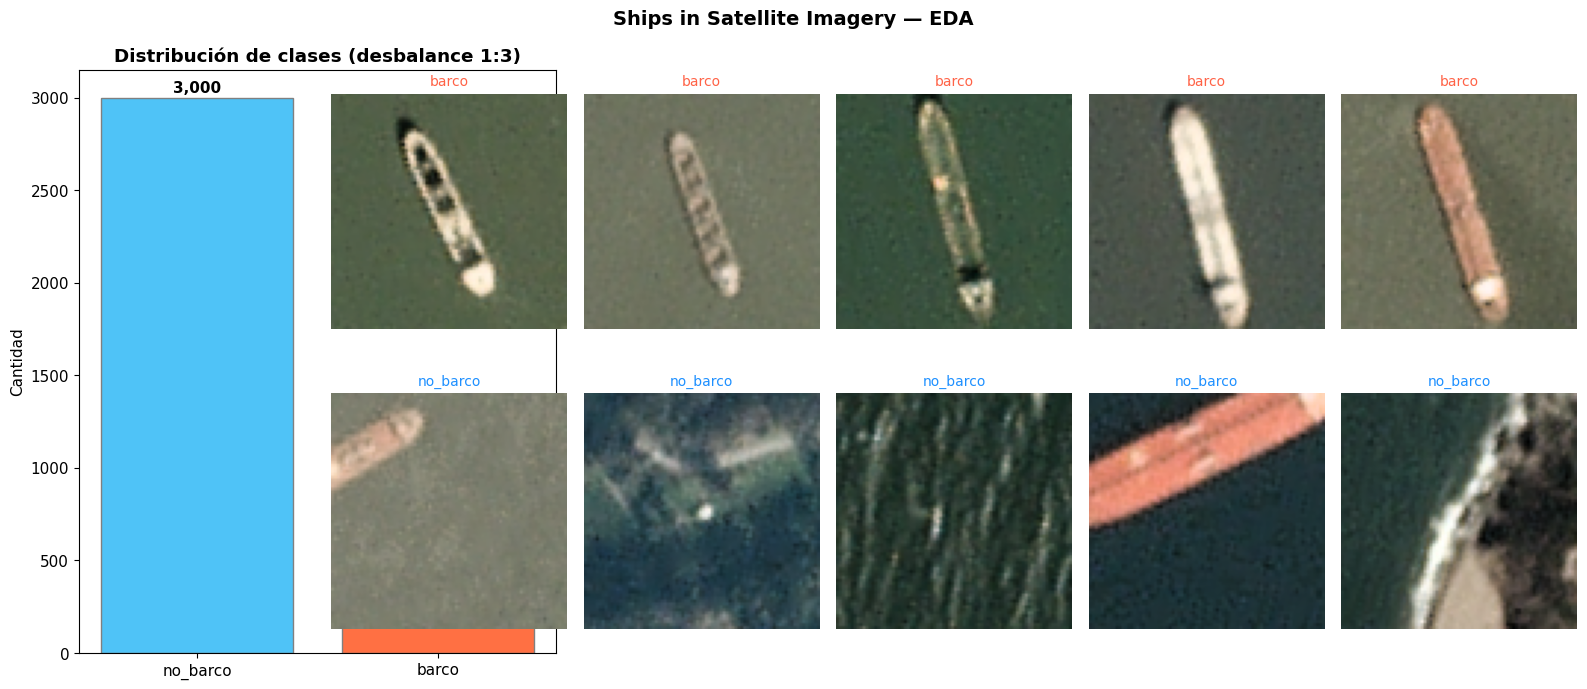

📐 Tamaño de cada recorte: (80, 80, 3)


In [6]:
# EDA: distribución de clases y muestras
fig = plt.figure(figsize=(16, 7))

# Distribución (gráfico de barras)
ax0 = fig.add_subplot(1, 3, 1)
counts = [(chip_labels == 0).sum(), (chip_labels == 1).sum()]
bars = ax0.bar(CLASS_NAMES_1, counts, color=['#4FC3F7', '#FF7043'], edgecolor='gray')
for b, c in zip(bars, counts):
    ax0.text(b.get_x() + b.get_width() / 2, b.get_height() + 30, f'{c:,}',
             ha='center', fontweight='bold')
ax0.set_title('Distribución de clases (desbalance 1:3)', fontweight='bold')
ax0.set_ylabel('Cantidad')

# Muestras: 5 barcos y 5 no barcos
rng = np.random.default_rng(SEED)
idx_ship = rng.choice(np.where(chip_labels == 1)[0], 5, replace=False)
idx_noship = rng.choice(np.where(chip_labels == 0)[0], 5, replace=False)
for k, idx in enumerate(list(idx_ship) + list(idx_noship)):
    ax = fig.add_subplot(2, 6, (k // 5) * 6 + (k % 5) + 2)
    img = tf.io.decode_png(tf.io.read_file(chip_paths[idx]), channels=3).numpy()
    ax.imshow(img)
    ax.set_title(CLASS_NAMES_1[chip_labels[idx]], fontsize=10,
                 color='tomato' if chip_labels[idx] == 1 else 'dodgerblue')
    ax.axis('off')

plt.suptitle('Ships in Satellite Imagery — EDA', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"📐 Tamaño de cada recorte: {img.shape}")

### 1.2. Preprocesamiento

1. **Lectura:** decodificamos los PNG con `tf.data` y los guardamos en caché (4,000 imágenes de 80×80 ocupan muy poca RAM).
2. **Augmentation (solo train):** flips horizontal/vertical y rotaciones de 90°. En una vista satelital no existe "arriba" ni "abajo".
3. **Resize 80×80 → 224×224** y `mobilenet_v2.preprocess_input` (píxeles en [-1, 1]).
4. **Etiqueta escalar (0/1):** como es binaria, la salida será **1 neurona sigmoide** con `binary_crossentropy`.

In [7]:
IMG_SIZE_1 = (224, 224)

def load_png(path, label):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    return img, label

def make_raw_ds(paths, labels, loader):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), np.array(labels, dtype=np.int32)))
    return ds.map(loader, num_parallel_calls=AUTOTUNE)

# Datasets "crudos" (uint8, 80×80) en caché
train_raw_1 = make_raw_ds(X_train_1, y_train_1, load_png).cache()
val_raw_1   = make_raw_ds(X_val_1,   y_val_1,   load_png).cache()
test_raw_1  = make_raw_ds(X_test_1,  y_test_1,  load_png).cache()

def augment_satelite(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    k = tf.random.uniform([], 0, 4, dtype=tf.int32)     # 0°, 90°, 180° o 270°
    image = tf.image.rot90(image, k)
    return image, label

def preprocess_example1(image, label):
    image = tf.image.resize(tf.cast(image, tf.float32), IMG_SIZE_1)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)   # → [-1, 1]
    return image, tf.cast(label, tf.float32)

train_ds_1 = (train_raw_1
    .shuffle(len(X_train_1), seed=SEED)
    .map(augment_satelite, num_parallel_calls=AUTOTUNE)
    .map(preprocess_example1, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

val_ds_1 = (val_raw_1
    .map(preprocess_example1, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

test_ds_1 = (test_raw_1
    .map(preprocess_example1, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

# Verificar un batch
for imgs, labels in train_ds_1.take(1):
    print(f"✅ Batch shape: {imgs.shape}")
    print(f"✅ Labels shape: {labels.shape}  →  ejemplo: {labels[:8].numpy()}")
    print(f"✅ Rango de píxeles: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")

✅ Batch shape: (32, 224, 224, 3)
✅ Labels shape: (32,)  →  ejemplo: [0. 0. 0. 0. 0. 0. 0. 0.]
✅ Rango de píxeles: [-0.96, 1.00]


### 1.3. Construir modelo con Feature Extraction

**Pasos clave:**
1. Cargar MobileNetV2 **sin** el clasificador (`include_top=False`)
2. **Congelar** todas sus capas (`trainable = False`)
3. Agregar un clasificador binario: `GlobalAveragePooling2D → Dropout → Dense(1, sigmoid)`

> La salida sigmoide da directamente **P(barco)**. Con 2 clases es equivalente a usar softmax de 2 neuronas, pero con la mitad de parámetros en la última capa.

In [8]:
# 1. Cargar backbone pre-entrenado (SIN clasificador de ImageNet)
base_model_1 = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE_1, 3)
)

# 2. CONGELAR todo el backbone
base_model_1.trainable = False

print(f"📐 Backbone: MobileNetV2")
print(f"📐 Capas totales: {len(base_model_1.layers)}")
print(f"📐 Parámetros totales: {base_model_1.count_params():,}")
print(f"📐 Parámetros entrenables: 0  (todo congelado)")
print(f"📐 Output shape: {base_model_1.output_shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
📐 Backbone: MobileNetV2
📐 Capas totales: 154
📐 Parámetros totales: 2,257,984
📐 Parámetros entrenables: 0  (todo congelado)
📐 Output shape: (None, 7, 7, 1280)


In [9]:
# 3. Construir modelo completo: backbone congelado + nuevo clasificador binario
inputs_1 = layers.Input(shape=(*IMG_SIZE_1, 3))
x = base_model_1(inputs_1, training=False)        # BatchNorm en modo inferencia
x = layers.GlobalAveragePooling2D(name='gap')(x)  # 7×7×1280 → 1280
x = layers.Dropout(0.3)(x)
outputs_1 = layers.Dense(1, activation='sigmoid', name='p_barco')(x)

model_1 = models.Model(inputs_1, outputs_1, name='ships_mobilenetv2_FE')
model_1.summary()

total = model_1.count_params()
trainable = sum(tf.size(w).numpy() for w in model_1.trainable_weights)
print(f"\n🔢 Total: {total:,} parámetros")
print(f"🔓 Entrenables: {trainable:,} ({trainable/total*100:.3f}%)")
print(f"🔒 Congelados: {total - trainable:,} ({(total-trainable)/total*100:.2f}%)")

Model: "ships_mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_barco (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


🔢 Total: 2,259,265 parámetros
🔓 Entrenables: 1,281 (0.057%)
🔒 Congelados: 2,257,984 (99.94%)


> 💡 **Observa:** solo se entrenan **1,281 parámetros** (1280 pesos + 1 bias). Los ~2.2M del backbone están congelados.

### 1.4. Entrenar con pesos de clase

Como hay 3 veces más "no barco" que "barco", un modelo que siempre diga "no barco" ya tendría **75% de accuracy** sin haber aprendido nada. Para evitarlo:
- **`class_weight`**: cada error en la clase minoritaria (barco) pesa más en la función de pérdida.
- **Métricas adicionales**: `precision`, `recall` y `AUC`, que sí reflejan si el modelo detecta los barcos.

In [10]:
# Pesos de clase inversamente proporcionales a la frecuencia
n_neg, n_pos = np.bincount(y_train_1)
class_weight_1 = {0: (n_neg + n_pos) / (2 * n_neg),
                  1: (n_neg + n_pos) / (2 * n_pos)}
print(f"⚖️ class_weight: no_barco = {class_weight_1[0]:.3f} | barco = {class_weight_1[1]:.3f}")

model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)

history_1 = model_1.fit(
    train_ds_1,
    validation_data=val_ds_1,
    epochs=12,
    class_weight=class_weight_1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True)
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_1.history['val_accuracy']):.4f}")
print(f"🏆 Mejor val_auc:      {max(history_1.history['val_auc']):.4f}")

⚖️ class_weight: no_barco = 0.667 | barco = 2.000
Epoch 1/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 34s 216ms/step - accuracy: 0.8489 - auc: 0.9421 - loss: 0.3062 - precision: 0.6453 - recall: 0.8786 - val_accuracy: 0.8917 - val_auc: 0.9778 - val_loss: 0.2132 - val_precision: 0.7073 - val_recall: 0.9667
Epoch 2/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.9136 - auc: 0.9837 - loss: 0.1675 - precision: 0.7579 - recall: 0.9614 - val_accuracy: 0.9000 - val_auc: 0.9858 - val_loss: 0.1984 - val_precision: 0.7143 - val_recall: 1.0000
Epoch 3/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9279 - auc: 0.9879 - loss: 0.1457 - precision: 0.7929 - recall: 0.9629 - val_accuracy: 0.9250 - val_auc: 0.9890 - val_loss: 0.1552 - val_precision: 0.7749 - val_recall: 0.9867
Epoch 4/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9404 - auc: 0.9900 - loss: 0.1306 - precision: 0.8176 - recall: 0.9800 - val_accuracy: 0.9467 - val_auc: 0.9905 - val_loss: 0.1222 - val_precision: 0.8512 - va

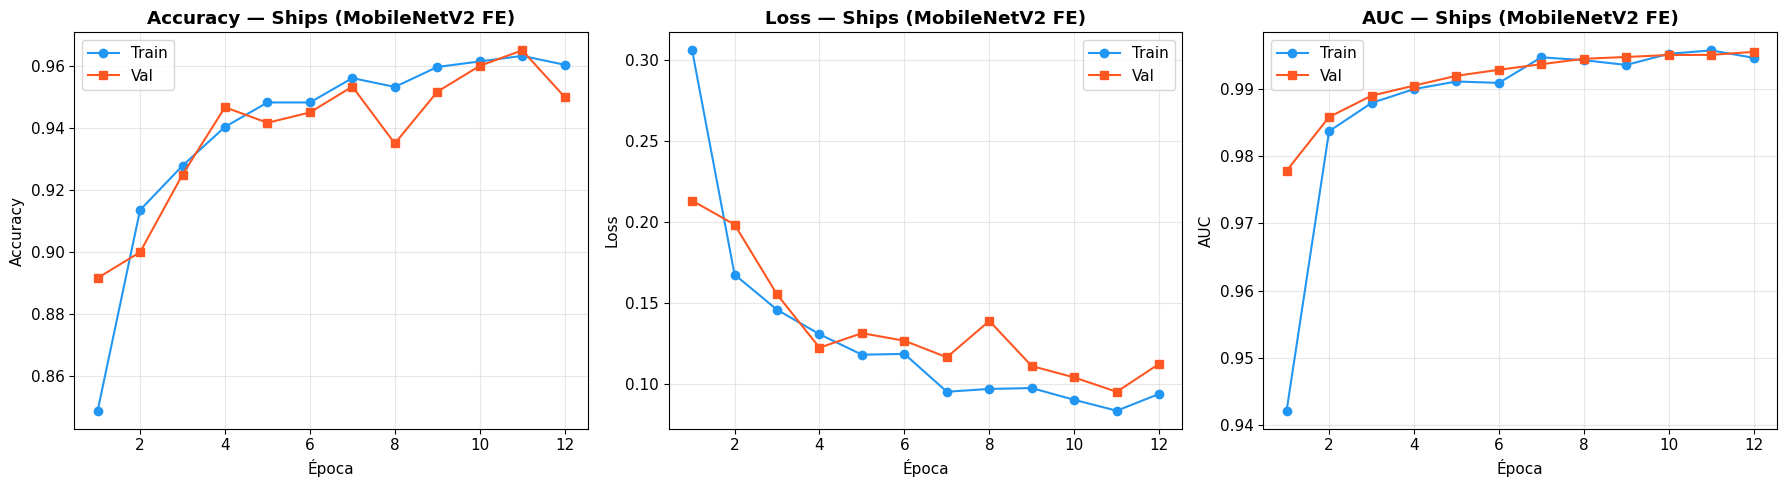

In [11]:
# Curvas de aprendizaje
h1 = history_1.history
ep = range(1, len(h1['accuracy']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metrica, titulo in [(axes[0], 'accuracy', 'Accuracy'),
                            (axes[1], 'loss', 'Loss'),
                            (axes[2], 'auc', 'AUC')]:
    ax.plot(ep, h1[metrica], 'o-', label='Train', color='#2196F3')
    ax.plot(ep, h1['val_' + metrica], 's-', label='Val', color='#FF5722')
    ax.set_title(f'{titulo} — Ships (MobileNetV2 FE)', fontweight='bold')
    ax.set_xlabel('Época'); ax.set_ylabel(titulo)
    ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5. Evaluación en el conjunto de TEST

Evaluamos en datos que el modelo **nunca vio** (ni para entrenar ni para elegir la mejor época).

In [12]:
# Probabilidades P(barco) sobre test (el orden coincide con X_test_1 / y_test_1)
probs_test_1 = model_1.predict(test_ds_1, verbose=0).ravel()
UMBRAL_1 = 0.5
y_pred_1 = (probs_test_1 >= UMBRAL_1).astype(int)

print("📊 Classification Report — Ships (MobileNetV2 FE) — TEST")
print("=" * 65)
print(classification_report(y_test_1, y_pred_1, target_names=CLASS_NAMES_1, digits=4))
print(f"🎯 ROC-AUC (test): {roc_auc_score(y_test_1, probs_test_1):.4f}")

📊 Classification Report — Ships (MobileNetV2 FE) — TEST
              precision    recall  f1-score   support

    no_barco     0.9930    0.9444    0.9681       450
       barco     0.8547    0.9800    0.9130       150

    accuracy                         0.9533       600
   macro avg     0.9238    0.9622    0.9406       600
weighted avg     0.9584    0.9533    0.9543       600

🎯 ROC-AUC (test): 0.9949


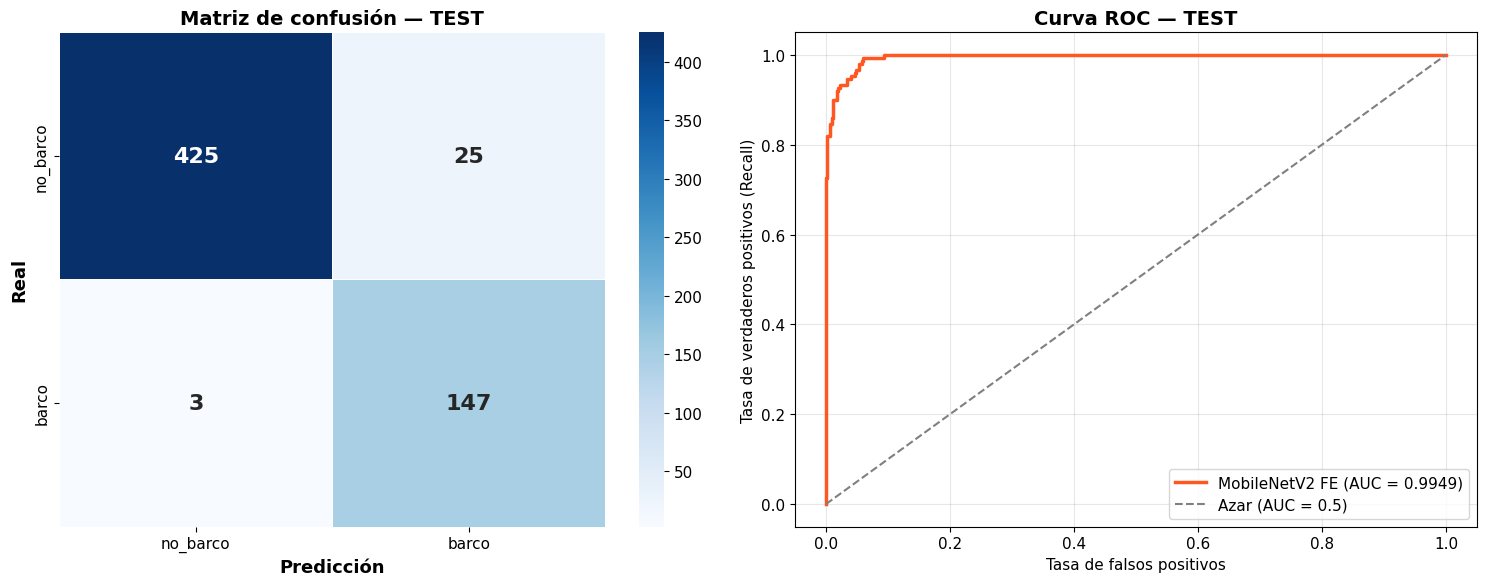

✅ Barcos detectados correctamente (TP): 147
❌ Barcos que se escaparon (FN):        3
⚠️ Falsas alarmas (FP):                 25


In [13]:
# Matriz de confusión + Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cm_1 = confusion_matrix(y_test_1, y_pred_1)
sns.heatmap(cm_1, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES_1, yticklabels=CLASS_NAMES_1, ax=axes[0],
            linewidths=0.5, linecolor='white', annot_kws={'size': 16, 'fontweight': 'bold'})
axes[0].set_xlabel('Predicción', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Real', fontsize=13, fontweight='bold')
axes[0].set_title('Matriz de confusión — TEST', fontsize=14, fontweight='bold')

fpr, tpr, _ = roc_curve(y_test_1, probs_test_1)
auc_1 = roc_auc_score(y_test_1, probs_test_1)
axes[1].plot(fpr, tpr, color='#FF5722', linewidth=2.5, label=f'MobileNetV2 FE (AUC = {auc_1:.4f})')
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Azar (AUC = 0.5)')
axes[1].set_xlabel('Tasa de falsos positivos'); axes[1].set_ylabel('Tasa de verdaderos positivos (Recall)')
axes[1].set_title('Curva ROC — TEST', fontsize=14, fontweight='bold')
axes[1].legend(loc='lower right'); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_1.ravel()
print(f"✅ Barcos detectados correctamente (TP): {tp}")
print(f"❌ Barcos que se escaparon (FN):        {fn}")
print(f"⚠️ Falsas alarmas (FP):                 {fp}")

### 1.6. Predicciones visuales y análisis de errores

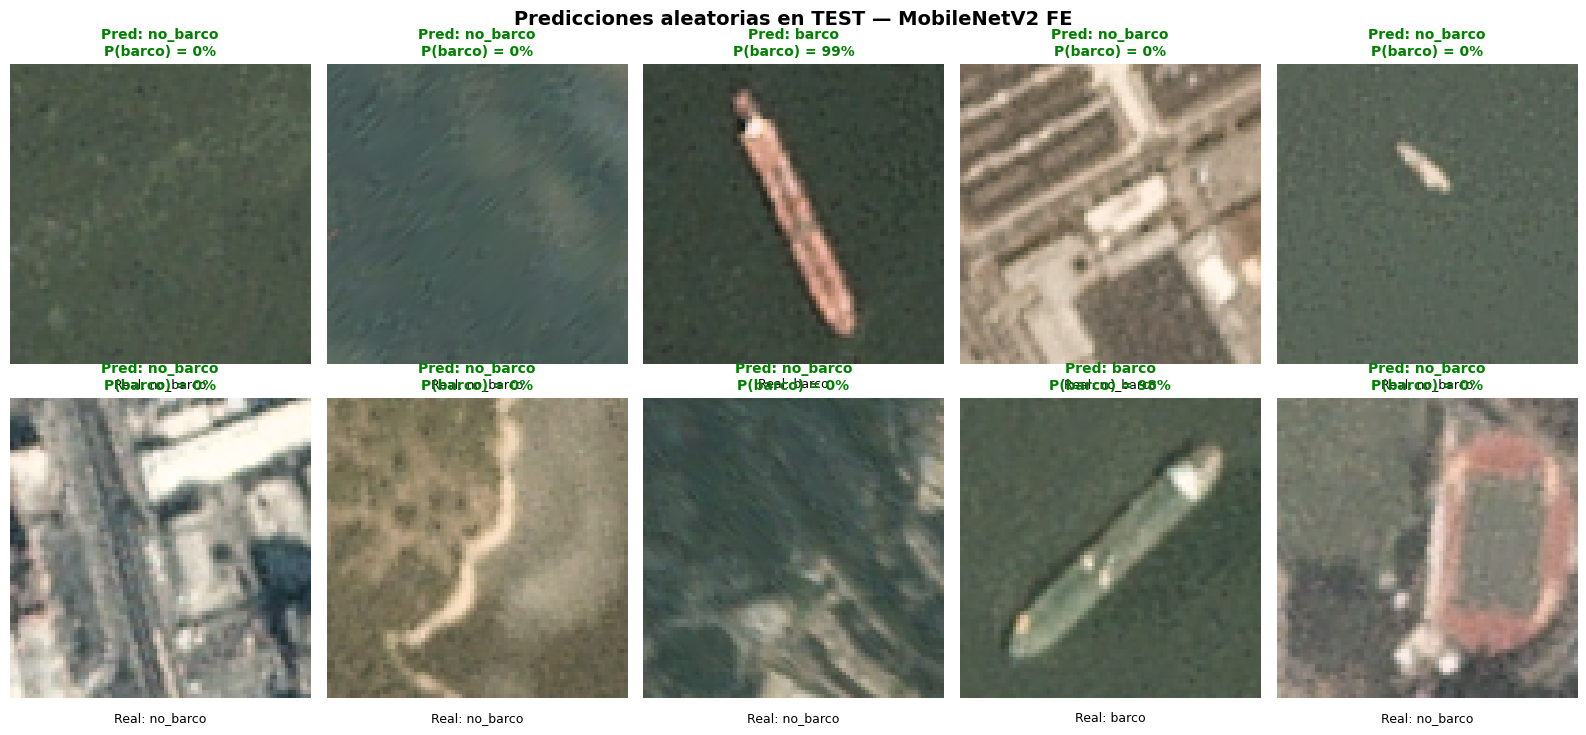

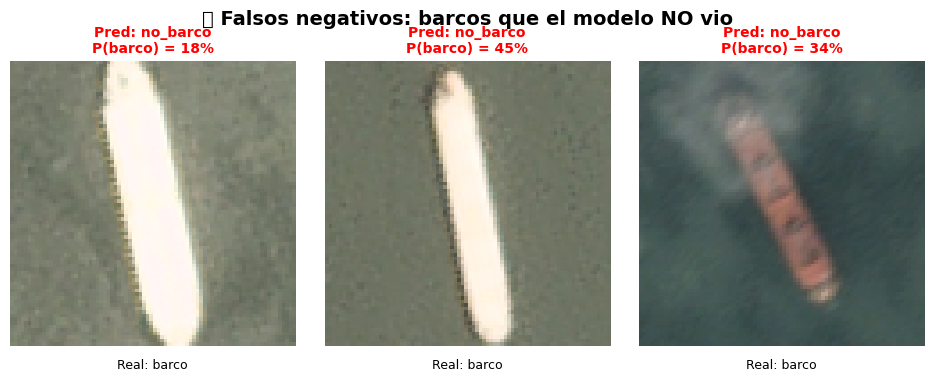

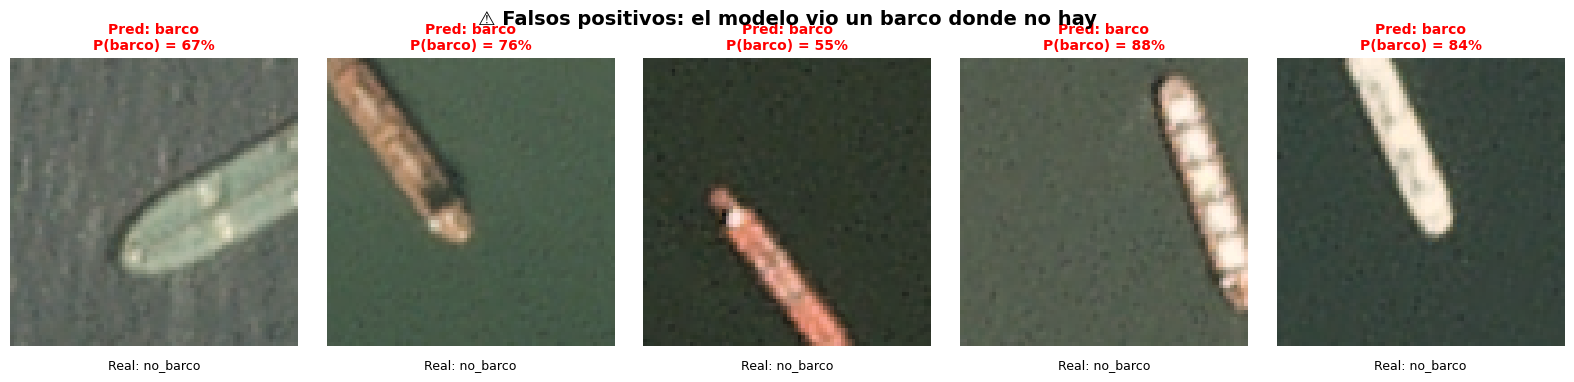

In [14]:
def mostrar_chips(indices, titulo):
    n = len(indices)
    if n == 0:
        print(f"(sin imágenes para: {titulo})")
        return
    cols = min(n, 5); rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, i in zip(axes.ravel(), indices):
        img = tf.io.decode_png(tf.io.read_file(X_test_1[i]), channels=3).numpy()
        pred = CLASS_NAMES_1[y_pred_1[i]]; real = CLASS_NAMES_1[y_test_1[i]]
        ax.imshow(img)
        ax.set_title(f"Pred: {pred}\nP(barco) = {probs_test_1[i]:.0%}", fontsize=10,
                     color='green' if pred == real else 'red', fontweight='bold')
        ax.text(0.5, -0.08, f"Real: {real}", transform=ax.transAxes, ha='center', fontsize=9)
    plt.suptitle(titulo, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)
mostrar_chips(rng.choice(len(X_test_1), 10, replace=False),
              'Predicciones aleatorias en TEST — MobileNetV2 FE')

idx_fn = np.where((y_test_1 == 1) & (y_pred_1 == 0))[0][:5]
idx_fp = np.where((y_test_1 == 0) & (y_pred_1 == 1))[0][:5]
mostrar_chips(idx_fn, '❌ Falsos negativos: barcos que el modelo NO vio')
mostrar_chips(idx_fp, '⚠️ Falsos positivos: el modelo vio un barco donde no hay')

> 📝 **Analiza los errores:** los falsos positivos suelen ser **barcos cortados a la mitad**, muelles o estructuras alargadas (en el dataset están etiquetados como "no barco"). Los falsos negativos suelen ser barcos muy pequeños o con poco contraste respecto al agua.

### 1.7. 🌍 Aplicación real: escanear una escena satelital completa

El modelo clasifica recortes de 80×80. Para usarlo en una imagen satelital grande, la recorremos con una **ventana deslizante** de 80×80 (paso de 40 px), clasificamos cada ventana y marcamos las que superen un umbral de confianza alto.

> Así se convierte un **clasificador** en un **detector** sencillo, que es lo que necesitaría un sistema de vigilancia marítima.

In [15]:
SCENE_IDX = 0      # ⚙️ prueba con 0, 1, 2, ... según cuántas escenas haya
WIN, STRIDE = 80, 40
UMBRAL_ESCENA = 0.90   # umbral alto para reducir falsas alarmas

if len(scene_paths) == 0:
    print("⚠️ No se encontraron escenas completas en el dataset.")
else:
    scene = tf.io.decode_png(tf.io.read_file(scene_paths[SCENE_IDX]), channels=3).numpy()
    H, W, _ = scene.shape
    print(f"🗺️ Escena: {os.path.basename(scene_paths[SCENE_IDX])} — {W}×{H} px")

    # Generar ventanas
    coords, crops = [], []
    for yy in range(0, H - WIN + 1, STRIDE):
        for xx in range(0, W - WIN + 1, STRIDE):
            coords.append((xx, yy))
            crops.append(scene[yy:yy + WIN, xx:xx + WIN])
    crops = np.stack(crops)
    print(f"🔍 Ventanas a clasificar: {len(crops):,}")

    # Clasificar en lotes
    t0 = time.time()
    probs_scene = []
    for i in range(0, len(crops), 256):
        lote = tf.image.resize(tf.cast(crops[i:i + 256], tf.float32), IMG_SIZE_1)
        lote = tf.keras.applications.mobilenet_v2.preprocess_input(lote)
        probs_scene.append(model_1.predict(lote, verbose=0).ravel())
    probs_scene = np.concatenate(probs_scene)
    print(f"⏱️ Tiempo de escaneo: {time.time() - t0:.1f} s")

    # Dibujar detecciones
    detecciones = [(c, p) for c, p in zip(coords, probs_scene) if p >= UMBRAL_ESCENA]
    fig, ax = plt.subplots(figsize=(18, 18 * H / W))
    ax.imshow(scene)
    for (xx, yy), p in detecciones:
        ax.add_patch(plt.Rectangle((xx, yy), WIN, WIN, fill=False,
                                   edgecolor='red', linewidth=1.5))
    ax.set_title(f'Detección de barcos por ventana deslizante — '
                 f'{len(detecciones)} ventanas con P(barco) ≥ {UMBRAL_ESCENA:.0%}',
                 fontsize=14, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.show()

⚠️ No se encontraron escenas completas en el dataset.


> 💡 Varias ventanas superpuestas pueden marcar **el mismo barco** porque el paso (40 px) es la mitad de la ventana. En un detector real se fusionarían con *Non-Maximum Suppression*; aquí basta para mostrar que el modelo **ubica los barcos en una escena que nunca vio**.

### ✅ Conclusión Ejemplo 1

In [16]:
resumen_1 = pd.DataFrame({
    'Métrica': ['Modelo base', 'Parámetros entrenados', 'Épocas ejecutadas',
                'Accuracy (test)', 'Precision barco (test)', 'Recall barco (test)',
                'F1 barco (test)', 'ROC-AUC (test)'],
    'Valor': ['MobileNetV2 (congelado)',
              f"{sum(tf.size(w).numpy() for w in model_1.trainable_weights):,}",
              len(history_1.history['loss']),
              f"{accuracy_score(y_test_1, y_pred_1):.4f}",
              f"{precision_score(y_test_1, y_pred_1):.4f}",
              f"{recall_score(y_test_1, y_pred_1):.4f}",
              f"{f1_score(y_test_1, y_pred_1):.4f}",
              f"{roc_auc_score(y_test_1, probs_test_1):.4f}"]
})
print(resumen_1.to_string(index=False))

               Métrica                   Valor
           Modelo base MobileNetV2 (congelado)
 Parámetros entrenados                   1,281
     Épocas ejecutadas                      12
       Accuracy (test)                  0.9533
Precision barco (test)                  0.8547
   Recall barco (test)                  0.9800
       F1 barco (test)                  0.9130
        ROC-AUC (test)                  0.9949


> **Interpretación (completar con tus resultados):** con solo ~1,300 parámetros entrenables, MobileNetV2 transfiere los features de ImageNet a imágenes satelitales, un dominio muy distinto. En vigilancia marítima el **recall de la clase barco** es la métrica clave: un barco no detectado (FN) cuesta más que una falsa alarma (FP), que un operador puede descartar.

---
# 🟡 Ejemplo 2 — Intermedio: Variedades de arroz con EfficientNetB0

**Objetivo:** Feature Extraction **multiclase** (5 variedades), con EDA, Data Augmentation, métricas avanzadas (matriz de confusión, classification report) y visualización de feature maps.

**Dataset:** [Rice Image Dataset](https://www.kaggle.com/datasets/muratkokludataset/rice-image-dataset) (Koklu et al., 2021) — **75,000 imágenes** de granos individuales sobre fondo negro, **250×250 px**, 15,000 por variedad:

| Variedad | Característica visual |
|---|---|
| **Arborio** | Grano corto, ancho y redondeado |
| **Basmati** | Grano muy largo y delgado |
| **Ipsala** | Grano grande y ancho |
| **Jasmine** | Grano largo, algo más corto que Basmati |
| **Karacadag** | Grano pequeño y redondeado |

**¿Por qué EfficientNetB0?** Es el mejor balance accuracy/eficiencia de su generación y un "upgrade" natural sobre MobileNetV2.

> ⚙️ **Subconjunto:** con 75,000 imágenes cada época tardaría mucho en Colab. Trabajamos con `SAMPLES_PER_CLASS` imágenes por clase (2,000 por defecto = 10,000 en total). Puedes subirlo si tienes tiempo de GPU.

### 2.1. Descargar dataset y EDA

In [18]:
# Descargar dataset
path_rice = kagglehub.dataset_download("muratkokludataset/rice-image-dataset")
print("📁 Carpeta del dataset:", path_rice)

for root, dirs, files in os.walk(path_rice):
    nivel = root.replace(path_rice, '').count(os.sep)
    if nivel <= 3:
        print('   ' * nivel + f"📂 {os.path.basename(root) or root}  ({len(files)} archivos)")

Using Colab cache for faster access to the 'rice-image-dataset' dataset.
📁 Carpeta del dataset: /kaggle/input/rice-image-dataset
📂 rice-image-dataset  (0 archivos)
   📂 Rice_Image_Dataset  (1 archivos)
      📂 Karacadag  (15000 archivos)
      📂 Basmati  (15000 archivos)
      📂 Jasmine  (15000 archivos)
      📂 Arborio  (15000 archivos)
      📂 Ipsala  (15000 archivos)


In [19]:
# Listar imágenes: la clase es el nombre de la carpeta que contiene la imagen
rice_files = []
for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG'):
    rice_files += glob.glob(os.path.join(path_rice, '**', ext), recursive=True)

df_rice = pd.DataFrame({'path': rice_files})
df_rice['clase'] = df_rice['path'].apply(lambda p: os.path.basename(os.path.dirname(p)))
df_rice['archivo'] = df_rice['path'].apply(os.path.basename)
df_rice = df_rice.drop_duplicates(subset=['clase', 'archivo']).reset_index(drop=True)

CLASS_NAMES_2 = sorted(df_rice['clase'].unique())
NUM_CLASSES_2 = len(CLASS_NAMES_2)
class_to_idx_2 = {c: i for i, c in enumerate(CLASS_NAMES_2)}
df_rice['label'] = df_rice['clase'].map(class_to_idx_2)

print(f"🌾 Clases ({NUM_CLASSES_2}): {CLASS_NAMES_2}")
print(f"📊 Total de imágenes: {len(df_rice):,}")
print(df_rice['clase'].value_counts().sort_index().to_string())

🌾 Clases (5): ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
📊 Total de imágenes: 75,000
clase
Arborio      15000
Basmati      15000
Ipsala       15000
Jasmine      15000
Karacadag    15000


In [20]:
# Verificar tamaños de imagen en una muestra
from PIL import Image
muestra = df_rice.sample(200, random_state=SEED)
tamanos = muestra['path'].apply(lambda p: Image.open(p).size).value_counts()
print("📐 Tamaños de imagen encontrados (muestra de 200):")
print(tamanos.to_string())

📐 Tamaños de imagen encontrados (muestra de 200):
path
(250, 250)    200


In [21]:
# Tomar el subconjunto balanceado y dividir 70/15/15 estratificado
SAMPLES_PER_CLASS = 1000    # ⚙️ máximo 15000 (dataset completo)

df_sub = (df_rice.groupby('clase', group_keys=False)
                 .sample(n=min(SAMPLES_PER_CLASS, df_rice['clase'].value_counts().min()),
                         random_state=SEED)
                 .reset_index(drop=True))

df_tmp, df_test_2 = train_test_split(df_sub, test_size=0.15, stratify=df_sub['label'],
                                     random_state=SEED)
df_train_2, df_val_2 = train_test_split(df_tmp, test_size=0.15 / 0.85,
                                        stratify=df_tmp['label'], random_state=SEED)

print(f"📊 Subconjunto: {len(df_sub):,} imágenes")
print(f"📊 Train: {len(df_train_2):,} | Val: {len(df_val_2):,} | Test: {len(df_test_2):,}")

📊 Subconjunto: 5,000 imágenes
📊 Train: 3,500 | Val: 750 | Test: 750


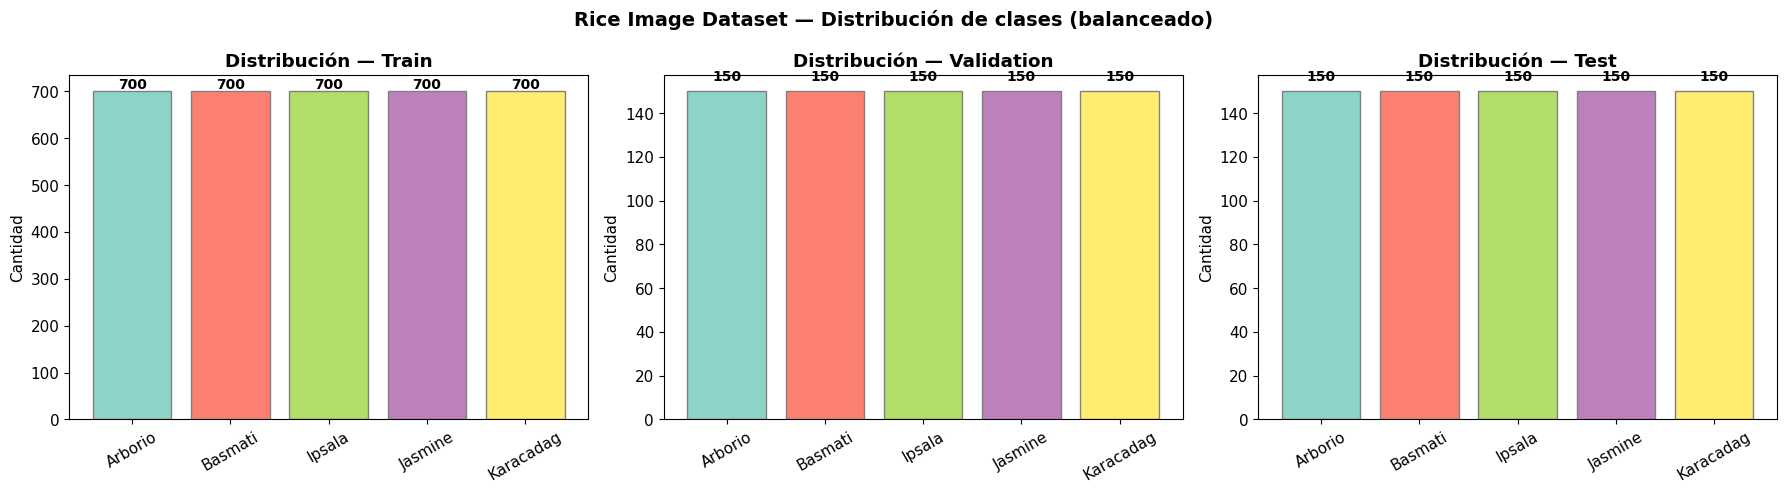

In [22]:
# Distribución de clases por conjunto
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES_2))

for ax, dfx, title_str in [(axes[0], df_train_2, 'Train'),
                           (axes[1], df_val_2, 'Validation'),
                           (axes[2], df_test_2, 'Test')]:
    counts = dfx['clase'].value_counts().reindex(CLASS_NAMES_2)
    bars = ax.bar(CLASS_NAMES_2, counts.values, color=colors, edgecolor='gray')
    ax.set_title(f'Distribución — {title_str}', fontweight='bold')
    ax.set_ylabel('Cantidad')
    for bar, count in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                str(count), ha='center', fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Rice Image Dataset — Distribución de clases (balanceado)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

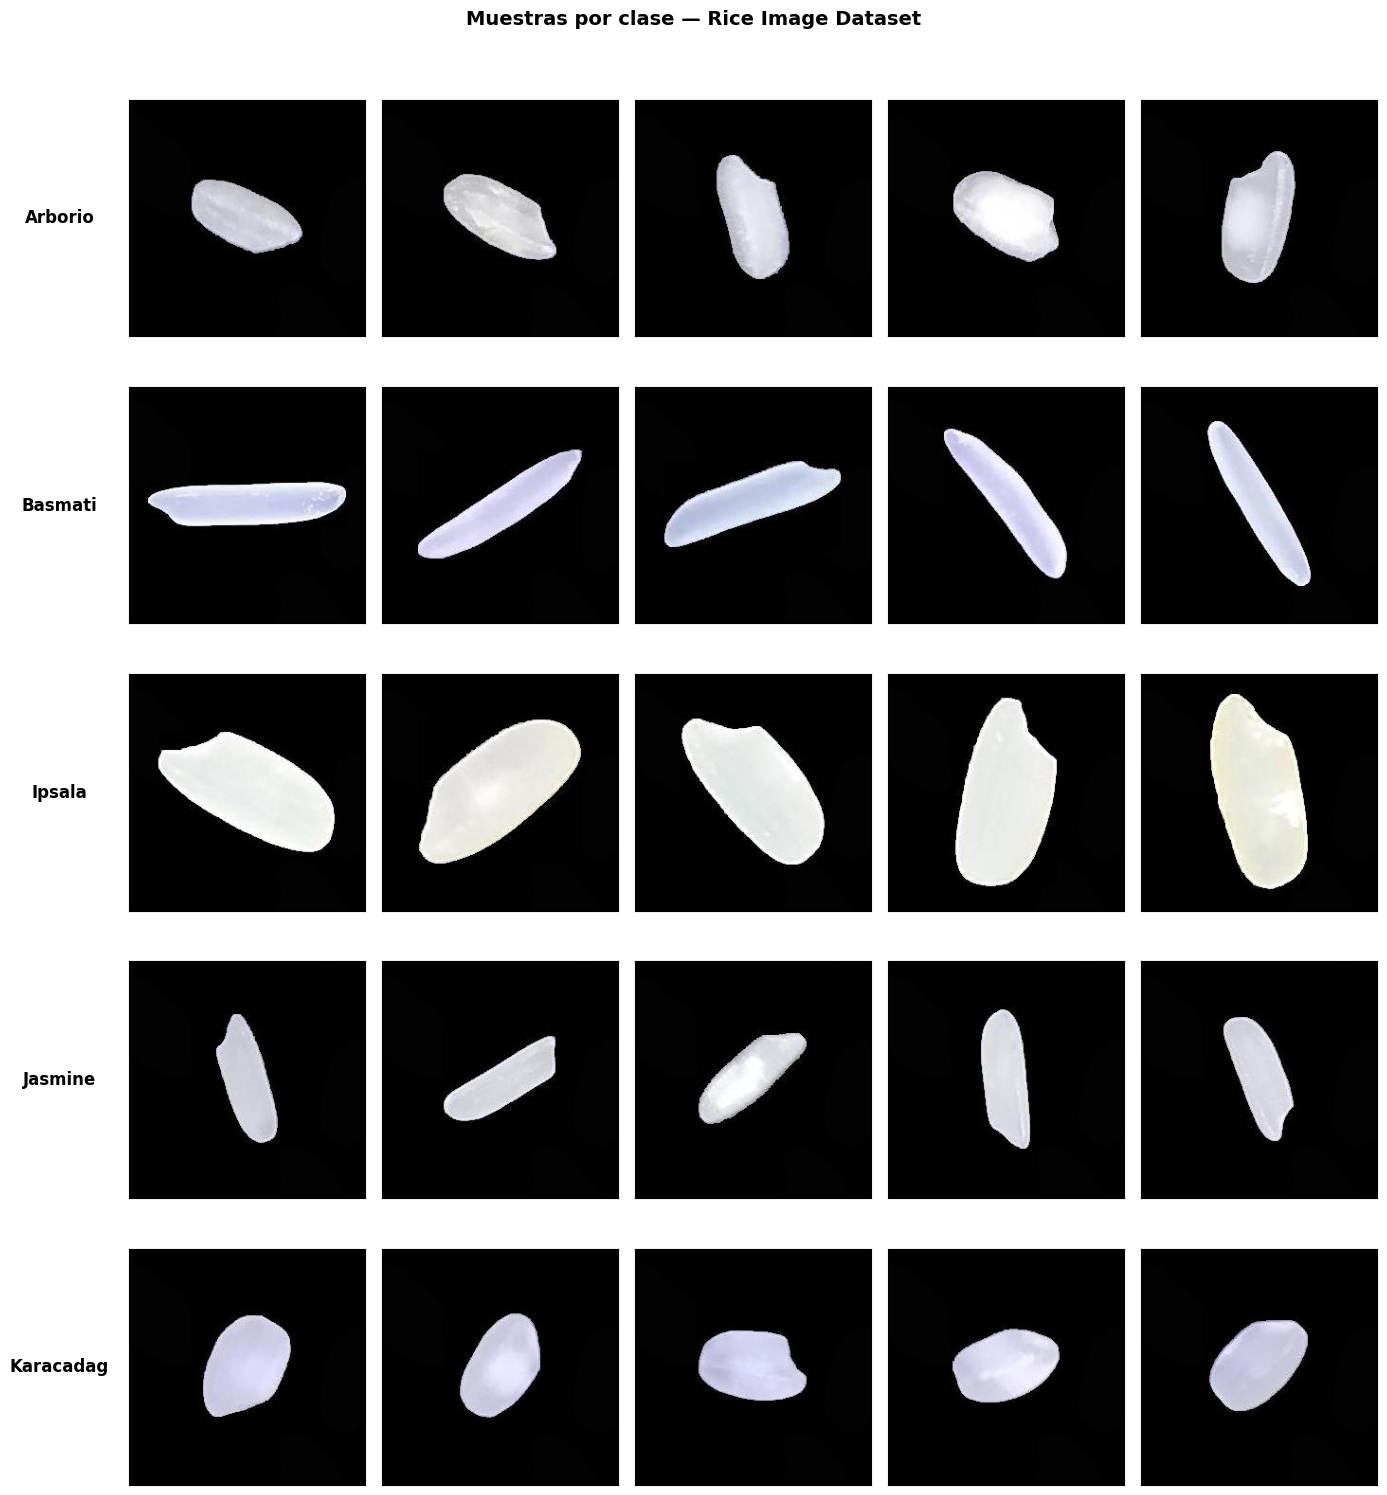

In [23]:
# Muestras por clase
fig, axes = plt.subplots(NUM_CLASSES_2, 5, figsize=(14, 3 * NUM_CLASSES_2))

for class_idx, clase in enumerate(CLASS_NAMES_2):
    ejemplos = df_train_2[df_train_2['clase'] == clase].sample(5, random_state=SEED)['path']
    for col, p in enumerate(ejemplos):
        ax = axes[class_idx, col]
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(clase, fontsize=12, fontweight='bold',
                          rotation=0, labelpad=50, va='center')

plt.suptitle('Muestras por clase — Rice Image Dataset', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

> 📝 **Observa:** las clases se distinguen sobre todo por **forma y proporción** del grano (largo/ancho) y algo por textura. Basmati y Jasmine (ambos largos) son las candidatas a confundirse.

### 2.2. Preprocesamiento con Data Augmentation

- Leemos y redimensionamos a **224×224** una sola vez y guardamos en caché en `uint8` (10,000 imágenes ≈ 1.5 GB de RAM).
- **Augmentation solo en train:** flips y rotación libre (el grano puede caer en cualquier orientación) y un leve desplazamiento y contraste.
- **No usamos zoom**: el **tamaño** del grano es información útil para distinguir variedades y no queremos alterarlo.
- `efficientnet.preprocess_input` espera píxeles en [0, 255] (la normalización está dentro del modelo).

In [24]:
IMG_SIZE_2 = (224, 224)

def load_rice(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE_2)
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)   # uint8 → caché liviana
    return img, label

# Datasets crudos en caché (si te quedas sin RAM usa .cache('/content/cache_train') etc.)
train_raw_2 = make_raw_ds(df_train_2['path'].values, df_train_2['label'].values, load_rice).cache()
val_raw_2   = make_raw_ds(df_val_2['path'].values,   df_val_2['label'].values,   load_rice).cache()
test_raw_2  = make_raw_ds(df_test_2['path'].values,  df_test_2['label'].values,  load_rice).cache()

# Capa de augmentation (solo se aplica en entrenamiento)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5, fill_mode='constant', fill_value=0.0),   # fondo negro
    layers.RandomTranslation(0.05, 0.05, fill_mode='constant', fill_value=0.0),
    layers.RandomContrast(0.1),
], name='augmentation')

def preprocess_train_2(image, label):
    image = tf.cast(image, tf.float32)
    image = data_augmentation(image, training=True)
    image = tf.keras.applications.efficientnet.preprocess_input(image)
    return image, tf.one_hot(label, NUM_CLASSES_2)

def preprocess_val_2(image, label):
    image = tf.keras.applications.efficientnet.preprocess_input(tf.cast(image, tf.float32))
    return image, tf.one_hot(label, NUM_CLASSES_2)

train_ds_2 = (train_raw_2
    .shuffle(2000, seed=SEED)
    .map(preprocess_train_2, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds_2 = (val_raw_2
    .map(preprocess_val_2, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))
test_ds_2 = (test_raw_2
    .map(preprocess_val_2, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

print("✅ Pipelines listos con augmentation en train")

✅ Pipelines listos con augmentation en train


ValueError: Exception encountered when calling Sequential.call().

[1mInvalid input shape for input [[[[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  ...

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]

  [[0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]
   ...
   [0. 0. 0.]
   [0. 0. 0.]
   [0. 0. 0.]]]] with name 'keras_tensor_159' and path ''. Expected shape (224, 224, 3), but input has incompatible shape (1, 224, 224, 3)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)
  • training=True
  • mask=None
  • kwargs=<class 'inspect._empty'>

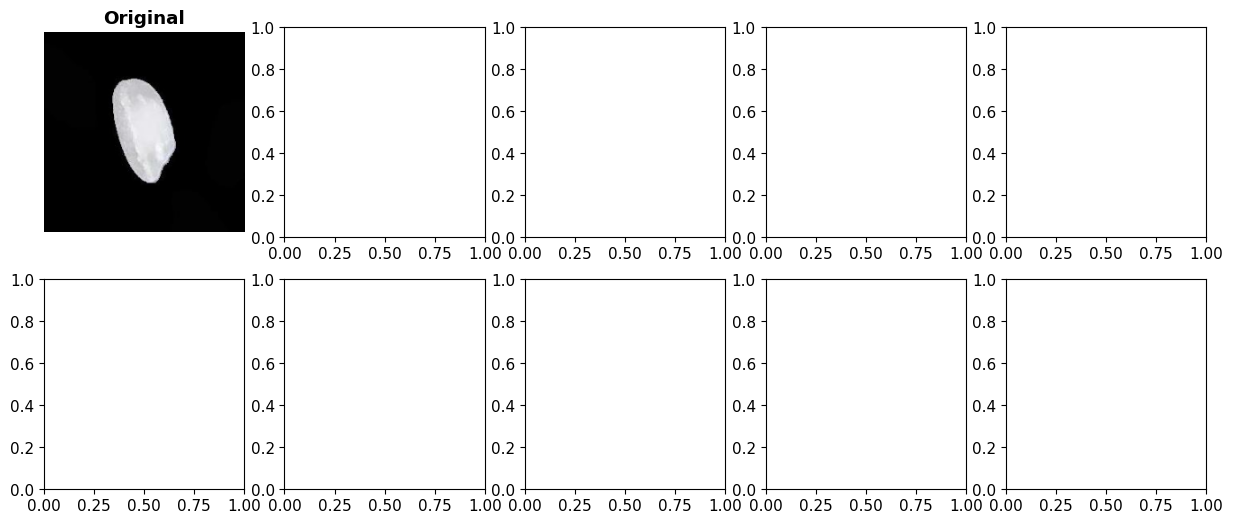

In [25]:
# Visualizar augmentation
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
sample_img, sample_label = next(iter(train_raw_2))
sample_float = tf.cast(sample_img, tf.float32)

axes[0, 0].imshow(sample_img.numpy())
axes[0, 0].set_title('Original', fontweight='bold')
axes[0, 0].axis('off')

for i in range(1, 10):
    ax = axes[i // 5, i % 5]
    augmented = data_augmentation(tf.expand_dims(sample_float, 0), training=True)
    ax.imshow(np.clip(augmented[0].numpy(), 0, 255).astype('uint8'))
    ax.set_title(f'Augmented #{i}', fontsize=10)
    ax.axis('off')

plt.suptitle(f'Data Augmentation — {CLASS_NAMES_2[sample_label.numpy()]}',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3. Construir modelo con EfficientNetB0

In [26]:
# Backbone EfficientNetB0
base_model_2 = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE_2, 3)
)
base_model_2.trainable = False  # Congelar

# Modelo con clasificador más robusto
inputs_2 = layers.Input(shape=(*IMG_SIZE_2, 3))
x = base_model_2(inputs_2, training=False)  # BN en modo inferencia
x = layers.GlobalAveragePooling2D(name='gap')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs_2 = layers.Dense(NUM_CLASSES_2, activation='softmax')(x)

model_2 = models.Model(inputs_2, outputs_2, name='rice_efficientnetb0_FE')

total = model_2.count_params()
trainable = sum(tf.size(w).numpy() for w in model_2.trainable_weights)
print(f"📐 EfficientNetB0 — Feature Extraction")
print(f"🔢 Total: {total:,} | 🔓 Entrenables: {trainable:,} | 🔒 Congelados: {total-trainable:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
📐 EfficientNetB0 — Feature Extraction
🔢 Total: 4,219,304 | 🔓 Entrenables: 167,173 | 🔒 Congelados: 4,052,131


### 2.4. Entrenar con callbacks profesionales

In [27]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_2 = model_2.fit(
    train_ds_2,
    validation_data=val_ds_2,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_2.history['val_accuracy']):.4f}")

Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 112s 664ms/step - accuracy: 0.9340 - loss: 0.1917 - val_accuracy: 0.9560 - val_loss: 0.2084 - learning_rate: 0.0010
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 37s 332ms/step - accuracy: 0.9686 - loss: 0.0916 - val_accuracy: 0.9787 - val_loss: 0.0849 - learning_rate: 0.0010
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 36s 325ms/step - accuracy: 0.9777 - loss: 0.0720 - val_accuracy: 0.9947 - val_loss: 0.0316 - learning_rate: 0.0010
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 42s 331ms/step - accuracy: 0.9737 - loss: 0.0846 - val_accuracy: 0.9893 - val_loss: 0.0323 - learning_rate: 0.0010
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 35s 319ms/step - accuracy: 0.9791 - loss: 0.0681 - val_accuracy: 0.9907 - val_loss: 0.0250 - learning_rate: 0.0010
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 42s 332ms/step - accuracy: 0.9843 - loss: 0.0434 - val_accuracy: 0.9800 - val_loss: 0.0477 - learning_rate: 0.0010
Epoch 7/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 334ms/step - accuracy: 0.

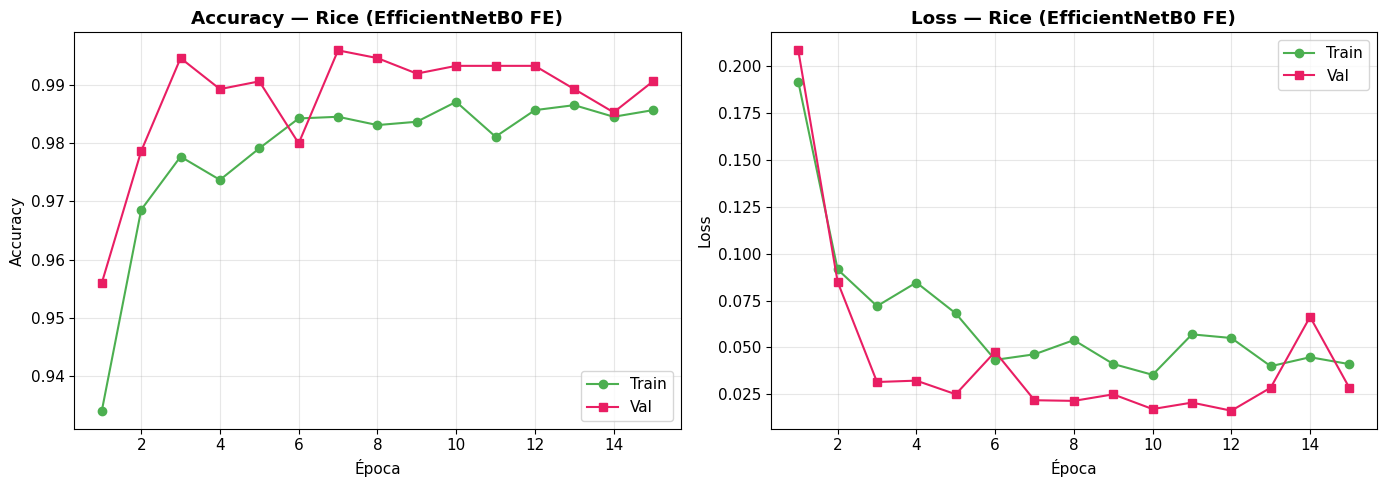

In [28]:
# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ep = range(1, len(history_2.history['accuracy']) + 1)
axes[0].plot(ep, history_2.history['accuracy'], 'o-', label='Train', color='#4CAF50')
axes[0].plot(ep, history_2.history['val_accuracy'], 's-', label='Val', color='#E91E63')
axes[0].set_title('Accuracy — Rice (EfficientNetB0 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history_2.history['loss'], 'o-', label='Train', color='#4CAF50')
axes[1].plot(ep, history_2.history['val_loss'], 's-', label='Val', color='#E91E63')
axes[1].set_title('Loss — Rice (EfficientNetB0 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.5. Evaluación detallada en TEST: Confusion Matrix + Classification Report

In [29]:
# Predicciones sobre test (el orden coincide con df_test_2)
probs_test_2 = model_2.predict(test_ds_2, verbose=0)
y_pred_2 = np.argmax(probs_test_2, axis=1)
y_true_2 = df_test_2['label'].values

print("📊 Classification Report — Rice (EfficientNetB0 FE) — TEST")
print("=" * 65)
print(classification_report(y_true_2, y_pred_2, target_names=CLASS_NAMES_2, digits=4))

📊 Classification Report — Rice (EfficientNetB0 FE) — TEST
              precision    recall  f1-score   support

     Arborio     0.9932    0.9667    0.9797       150
     Basmati     1.0000    0.9933    0.9967       150
      Ipsala     1.0000    1.0000    1.0000       150
     Jasmine     0.9933    0.9933    0.9933       150
   Karacadag     0.9677    1.0000    0.9836       150

    accuracy                         0.9907       750
   macro avg     0.9908    0.9907    0.9907       750
weighted avg     0.9908    0.9907    0.9907       750



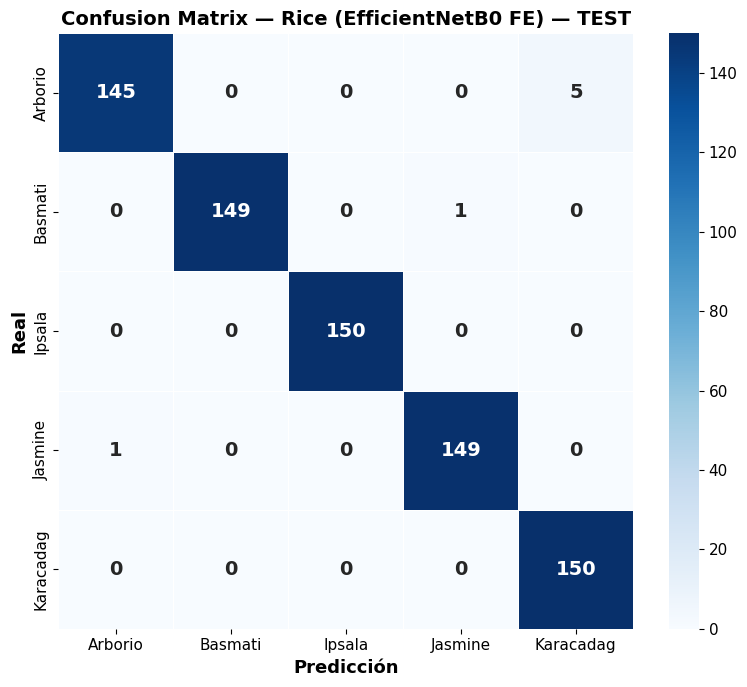


🔍 Principales confusiones:
   Arborio → Karacadag: 5 errores
   Basmati → Jasmine: 1 errores
   Jasmine → Arborio: 1 errores


In [30]:
# Confusion Matrix
cm_2 = confusion_matrix(y_true_2, y_pred_2)
fig, ax = plt.subplots(figsize=(8, 7))

sns.heatmap(cm_2, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES_2, yticklabels=CLASS_NAMES_2, ax=ax,
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 14, 'fontweight': 'bold'})

ax.set_xlabel('Predicción', fontsize=13, fontweight='bold')
ax.set_ylabel('Real', fontsize=13, fontweight='bold')
ax.set_title('Confusion Matrix — Rice (EfficientNetB0 FE) — TEST',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top errores
print("\n🔍 Principales confusiones:")
hay = False
for i in range(NUM_CLASSES_2):
    for j in range(NUM_CLASSES_2):
        if i != j and cm_2[i, j] > 0:
            print(f"   {CLASS_NAMES_2[i]} → {CLASS_NAMES_2[j]}: {cm_2[i, j]} errores")
            hay = True
if not hay:
    print("   ¡Ninguna! 🎉")

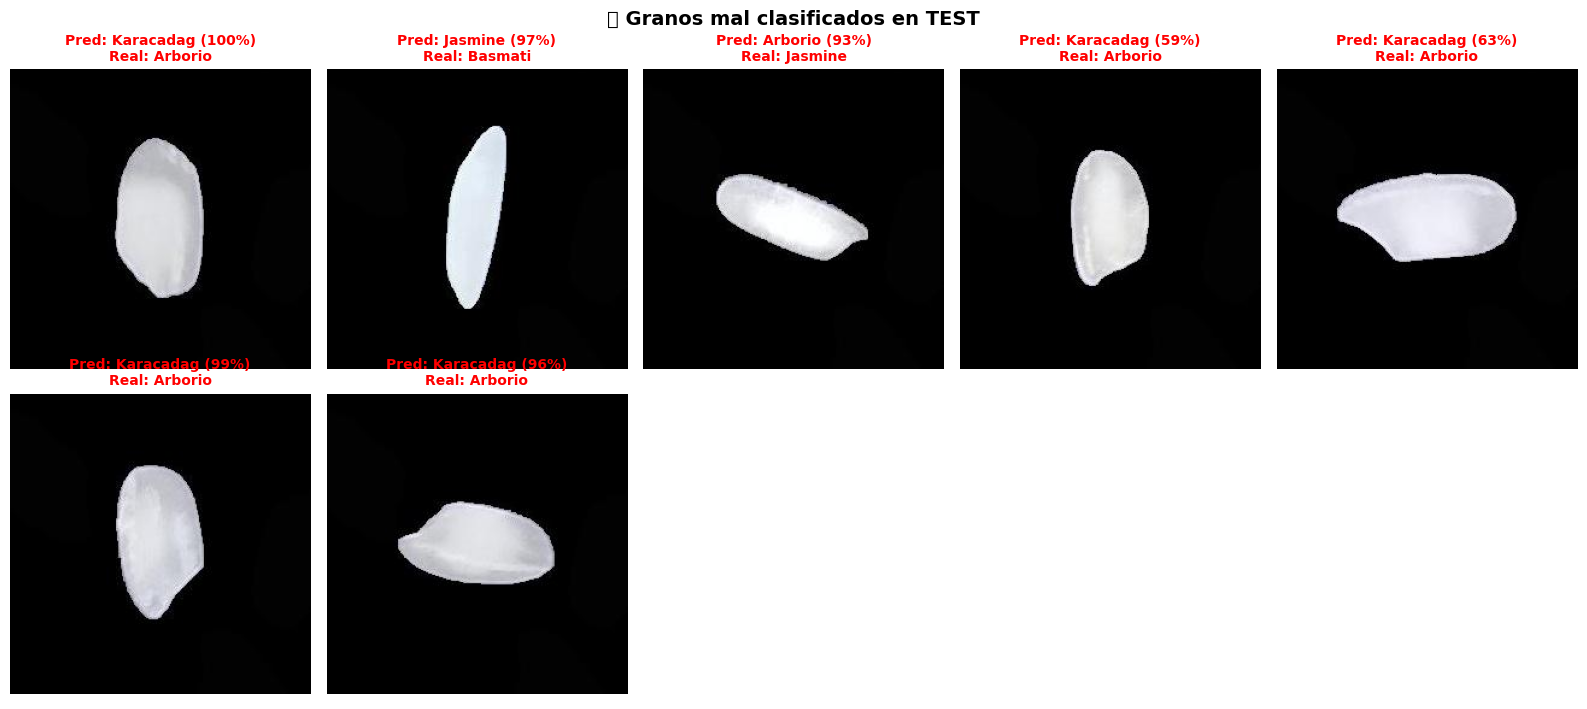

In [31]:
# Ejemplos mal clasificados
idx_err_2 = np.where(y_pred_2 != y_true_2)[0][:10]
if len(idx_err_2) == 0:
    print("🎉 No hay errores en test")
else:
    cols = min(len(idx_err_2), 5); rows = int(np.ceil(len(idx_err_2) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, i in zip(axes.ravel(), idx_err_2):
        ax.imshow(Image.open(df_test_2['path'].values[i]).convert('RGB'))
        ax.set_title(f"Pred: {CLASS_NAMES_2[y_pred_2[i]]} ({probs_test_2[i].max():.0%})\n"
                     f"Real: {CLASS_NAMES_2[y_true_2[i]]}", fontsize=10, color='red',
                     fontweight='bold')
    plt.suptitle('❌ Granos mal clasificados en TEST', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

### 2.6. Visualización de Feature Maps

¿Qué "ve" el backbone EfficientNetB0 en un grano de arroz? Extraemos los mapas de activación de capas clave.

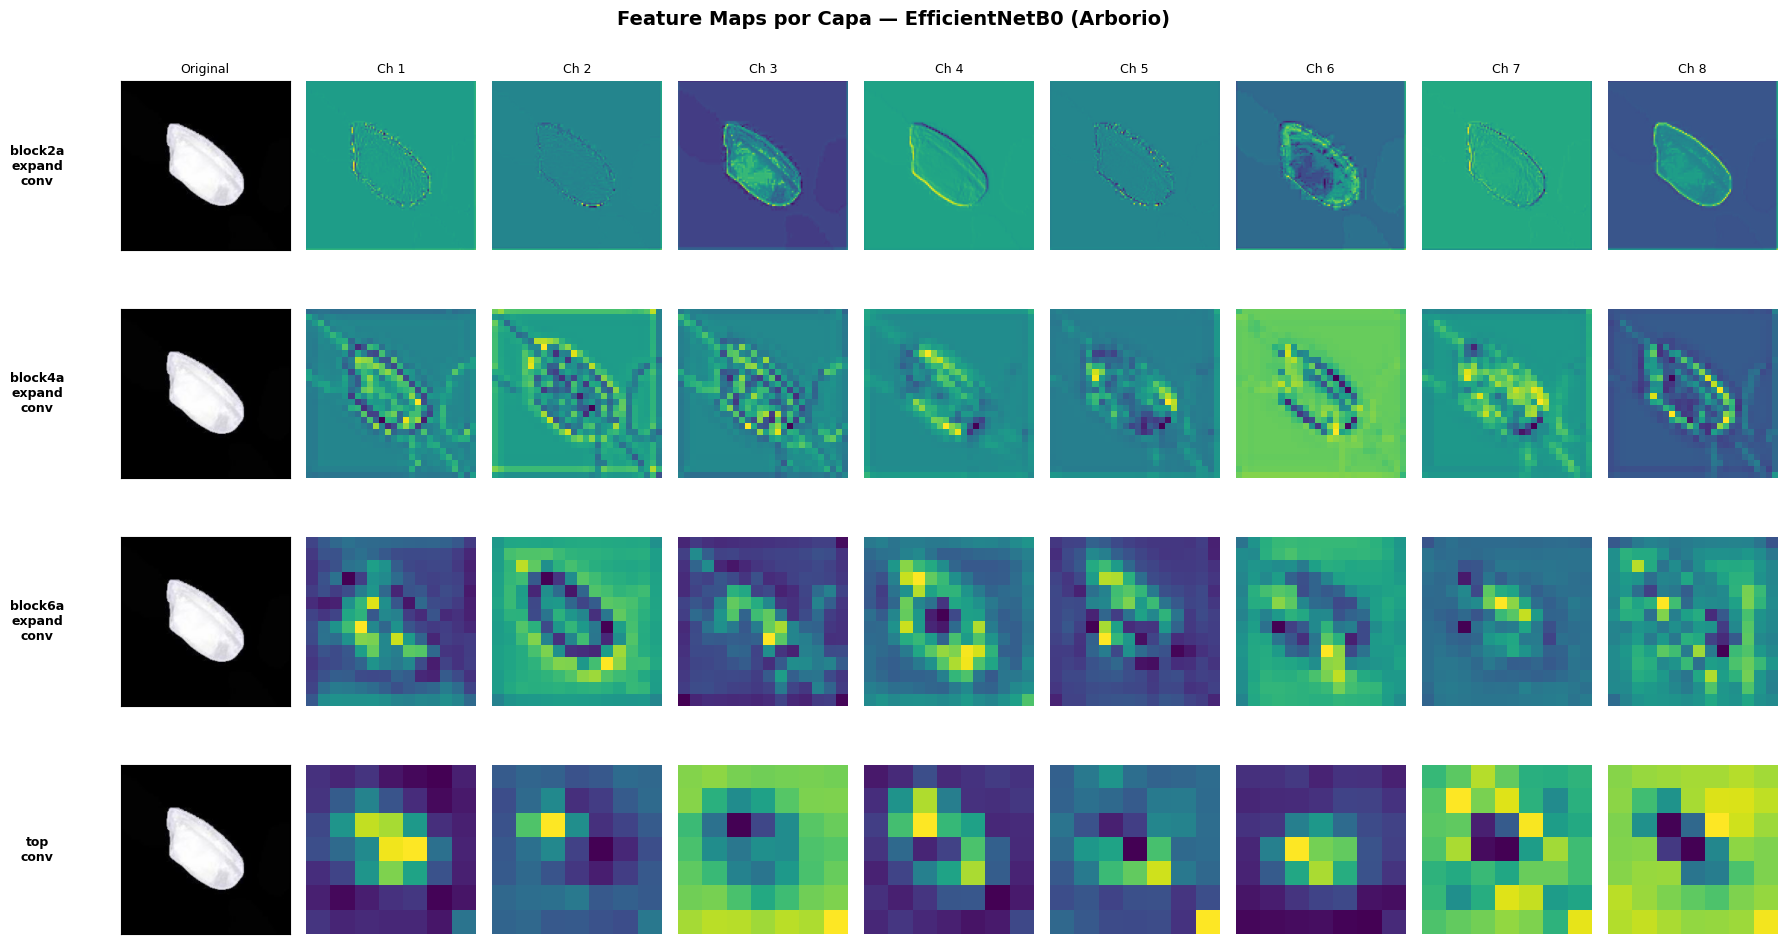

In [32]:
# Seleccionar capas para visualizar
layer_names = ['block2a_expand_conv', 'block4a_expand_conv', 'block6a_expand_conv', 'top_conv']
feature_models = [
    models.Model(inputs=base_model_2.input,
                 outputs=base_model_2.get_layer(name).output)
    for name in layer_names
]

# Tomar una imagen de ejemplo
sample_img_raw, sample_label_raw = next(iter(test_raw_2))
sample_processed = tf.keras.applications.efficientnet.preprocess_input(
    tf.expand_dims(tf.cast(sample_img_raw, tf.float32), 0))

fig, axes = plt.subplots(len(layer_names), 9, figsize=(18, 2.5 * len(layer_names)))

for row, (feat_model, layer_name) in enumerate(zip(feature_models, layer_names)):
    features = feat_model.predict(sample_processed, verbose=0)
    axes[row, 0].imshow(sample_img_raw.numpy())
    axes[row, 0].set_title('Original' if row == 0 else '', fontsize=9)
    axes[row, 0].set_ylabel(layer_name.replace('_', '\n'), fontsize=9,
                            fontweight='bold', rotation=0, labelpad=60, va='center')
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    for col in range(1, 9):
        ax = axes[row, col]
        if col - 1 < features.shape[-1]:
            ax.imshow(features[0, :, :, col - 1], cmap='viridis')
        ax.axis('off')
        if row == 0:
            ax.set_title(f'Ch {col}', fontsize=9)

plt.suptitle(f'Feature Maps por Capa — EfficientNetB0 '
             f'({CLASS_NAMES_2[sample_label_raw.numpy()]})',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> 📝 **Observa la progresión:** las capas tempranas resaltan el **contorno** del grano contra el fondo negro, las intermedias la **textura** y las zonas del grano, y las profundas son abstracciones de baja resolución que codifican forma y proporción, justo lo que diferencia una variedad de otra.

### ✅ Conclusión Ejemplo 2

In [33]:
resumen_2 = pd.DataFrame({
    'Métrica': ['Modelo base', 'Parámetros entrenados (head)', 'Imágenes usadas',
                'Épocas ejecutadas', 'Accuracy (test)', 'F1 macro (test)'],
    'Valor': ['EfficientNetB0 (congelado)',
              f"{sum(tf.size(w).numpy() for w in model_2.trainable_weights):,}",
              f"{len(df_sub):,} ({SAMPLES_PER_CLASS:,} por clase)",
              len(history_2.history['loss']),
              f"{accuracy_score(y_true_2, y_pred_2):.4f}",
              f"{f1_score(y_true_2, y_pred_2, average='macro'):.4f}"]
})
print(resumen_2.to_string(index=False))

                     Métrica                      Valor
                 Modelo base EfficientNetB0 (congelado)
Parámetros entrenados (head)                    167,173
             Imágenes usadas    5,000 (1,000 por clase)
           Épocas ejecutadas                         15
             Accuracy (test)                     0.9907
             F1 macro (test)                     0.9907


> **Interpretación (completar con tus resultados):** con ~165K parámetros entrenables y una fracción del dataset, EfficientNetB0 congelado distingue las 5 variedades. Revisa en la matriz de confusión qué pares se confunden (se espera Basmati ↔ Jasmine) y relaciónalo con la forma del grano.

---
# 🔴 Ejemplo 3 — Avanzado: Comparación de Backbones + t-SNE (arroz)

**Objetivo:** Comparar 4 backbones bajo las mismas condiciones para elegir el mejor para la clasificación de arroz, y visualizar con t-SNE cómo los features transferidos separan las variedades.

**Dataset:** Reutilizamos el subconjunto de arroz del Ejemplo 2 (mismos splits).

**Modelos a comparar:**
1. MobileNetV2 — Ligero, para dispositivos móviles
2. ResNet50 — Clásico, referencia de la industria
3. EfficientNetB0 — Balance accuracy/eficiencia
4. DenseNet121 — Conexiones densas, bueno con pocos datos

> ⚠️ **Preprocesamiento correcto por backbone:** cada red se entrenó en ImageNet con una normalización distinta. Solo EfficientNet trae la normalización incluida; MobileNetV2 espera [-1, 1], ResNet50 espera BGR con la media de ImageNet restada y DenseNet121 espera normalización tipo *torch*. Por eso **cada backbone recibe su propio `preprocess_input`** y la comparación es justa.

### 3.1. Función de benchmark

In [40]:
def make_ds(raw_ds, preprocess_fn, num_classes, shuffle=False, max_items=None):
    # Convierte un dataset crudo (uint8) en uno listo para un backbone concreto
    ds = raw_ds if max_items is None else raw_ds.take(max_items)
    if shuffle:
        ds = ds.shuffle(2000, seed=SEED)
    def _prep(img, label):
        return preprocess_fn(tf.cast(img, tf.float32)), tf.one_hot(label, num_classes)
    return ds.map(_prep, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)


def benchmark_backbone(backbone_fn, preprocess_fn, backbone_name,
                       train_raw, val_raw, test_raw, num_classes,
                       img_size=(224, 224), epochs=8, max_train=None):
    # Entrena Feature Extraction con un backbone y retorna métricas
    train_ds = make_ds(train_raw, preprocess_fn, num_classes, shuffle=True, max_items=max_train)
    val_ds = make_ds(val_raw, preprocess_fn, num_classes)
    test_ds = make_ds(test_raw, preprocess_fn, num_classes)

    base = backbone_fn(weights='imagenet', include_top=False, input_shape=(*img_size, 3))
    base.trainable = False

    inp = layers.Input(shape=(*img_size, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    model = models.Model(inp, out, name=f'rice_{backbone_name}_FE')

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])

    trainable_count = sum(tf.size(w).numpy() for w in model.trainable_weights)

    start_time = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
                        callbacks=[tf.keras.callbacks.EarlyStopping(
                            monitor='val_loss', patience=3, restore_best_weights=True)])
    train_time = time.time() - start_time

    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    return {
        'Backbone': backbone_name,
        'Params backbone': f"{base.count_params():,}",
        'Entrenables': f"{trainable_count:,}",
        'Best Val Acc': f"{max(history.history['val_accuracy']):.4f}",
        'Test Acc': f"{test_acc:.4f}",
        'Épocas': len(history.history['loss']),
        'Tiempo (s)': f"{train_time:.1f}",
        'model': model, 'history': history,
        'backbone_fn': backbone_fn, 'preprocess_fn': preprocess_fn,
    }

### 3.2. Ejecutar benchmark con 4 backbones

> ⏱️ Tarda varios minutos. Para que entre en una sesión de Colab usamos hasta `BENCH_MAX_TRAIN` imágenes de entrenamiento y `BENCH_EPOCHS` épocas como máximo (con EarlyStopping). Validación y test son los mismos del Ejemplo 2.

In [41]:
BENCH_MAX_TRAIN = 3500   # ⚙️ None = usar todo train_raw_2
BENCH_EPOCHS = 8

backbones = [
    (tf.keras.applications.MobileNetV2,    tf.keras.applications.mobilenet_v2.preprocess_input, 'MobileNetV2'),
    (tf.keras.applications.ResNet50,       tf.keras.applications.resnet50.preprocess_input,     'ResNet50'),
    (tf.keras.applications.EfficientNetB0, tf.keras.applications.efficientnet.preprocess_input, 'EfficientNetB0'),
    (tf.keras.applications.DenseNet121,    tf.keras.applications.densenet.preprocess_input,     'DenseNet121'),
]

results = []
for backbone_fn, prep_fn, name in backbones:
    print(f"\n{'='*50}")
    print(f"🔄 Entrenando: {name}")
    print('='*50)
    result = benchmark_backbone(
        backbone_fn, prep_fn, name,
        train_raw_2, val_raw_2, test_raw_2,
        NUM_CLASSES_2, epochs=BENCH_EPOCHS, max_train=BENCH_MAX_TRAIN
    )
    results.append(result)
    print(f"   ✅ {name}: val_acc = {result['Best Val Acc']}, test_acc = {result['Test Acc']}, "
          f"tiempo = {result['Tiempo (s)']}s")

print("\n🏁 Benchmark completado!")


🔄 Entrenando: MobileNetV2
   ✅ MobileNetV2: val_acc = 0.9867, test_acc = 0.9827, tiempo = 75.4s

🔄 Entrenando: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
   ✅ ResNet50: val_acc = 0.9960, test_acc = 0.9813, tiempo = 156.9s

🔄 Entrenando: EfficientNetB0
   ✅ EfficientNetB0: val_acc = 0.9987, test_acc = 0.9907, tiempo = 79.7s

🔄 Entrenando: DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
   ✅ DenseNet121: val_acc = 0.9973, test_acc = 0.9947, tiempo = 191.7s

🏁 Benchmark completado!


In [42]:
# Tabla comparativa
ocultar = ('model', 'history', 'backbone_fn', 'preprocess_fn')
df_results = pd.DataFrame([{k: v for k, v in r.items() if k not in ocultar} for r in results])
print("\n📊 TABLA COMPARATIVA DE BACKBONES — Rice Image Dataset")
print("=" * 95)
print(df_results.to_string(index=False))


📊 TABLA COMPARATIVA DE BACKBONES — Rice Image Dataset
      Backbone Params backbone Entrenables Best Val Acc Test Acc  Épocas Tiempo (s)
   MobileNetV2       2,257,984     167,173       0.9867   0.9827       8       75.4
      ResNet50      23,587,712     267,013       0.9960   0.9813       8      156.9
EfficientNetB0       4,049,571     167,173       0.9987   0.9907       8       79.7
   DenseNet121       7,037,504     133,893       0.9973   0.9947       8      191.7


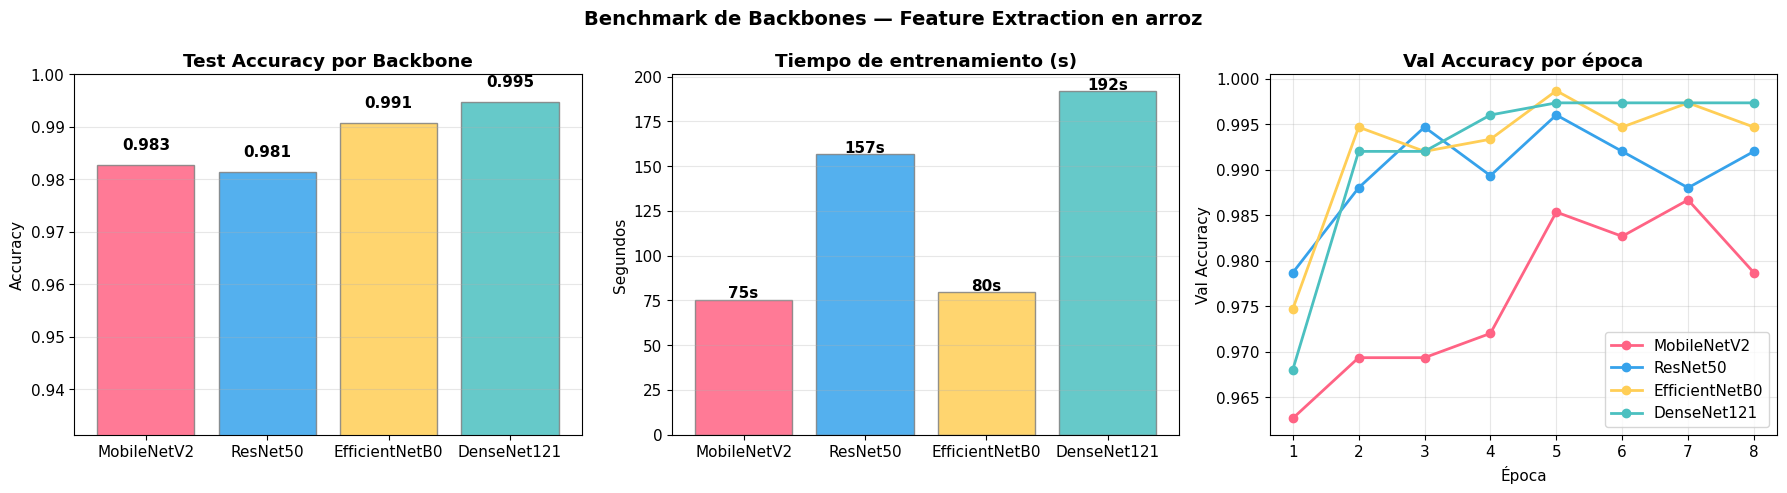

In [43]:
# Gráfico comparativo
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0']
names = [r['Backbone'] for r in results]

# 1. Test Accuracy por backbone
accs = [float(r['Test Acc']) for r in results]
bars = axes[0].bar(names, accs, color=colors, edgecolor='gray', alpha=0.85)
axes[0].set_title('Test Accuracy por Backbone', fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim([max(0, min(accs) - 0.05), min(1.0, max(accs) + 0.03)])
for bar, acc in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
                 f'{acc:.3f}', ha='center', fontweight='bold', fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')

# 2. Tiempo de entrenamiento
times = [float(r['Tiempo (s)']) for r in results]
bars2 = axes[1].bar(names, times, color=colors, edgecolor='gray', alpha=0.85)
axes[1].set_title('Tiempo de entrenamiento (s)', fontweight='bold')
axes[1].set_ylabel('Segundos')
for bar, t in zip(bars2, times):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                 f'{t:.0f}s', ha='center', fontweight='bold', fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

# 3. Curvas de val accuracy
for r, color in zip(results, colors):
    h = r['history']
    ep = range(1, len(h.history['val_accuracy']) + 1)
    axes[2].plot(ep, h.history['val_accuracy'], 'o-', label=r['Backbone'],
                 color=color, linewidth=2)
axes[2].set_title('Val Accuracy por época', fontweight='bold')
axes[2].set_xlabel('Época'); axes[2].set_ylabel('Val Accuracy')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle('Benchmark de Backbones — Feature Extraction en arroz', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.3. Visualización t-SNE de features transferidos

**t-SNE** (t-distributed Stochastic Neighbor Embedding) proyecta los features de alta dimensión del backbone (salida de la capa `gap`) a 2D. Si los puntos de cada variedad forman clusters separados, el Transfer Learning está funcionando.

In [44]:
from sklearn.manifold import TSNE

def extract_features(model, dataset, max_samples=600):
    # Extrae los features de la capa GAP (antes del clasificador)
    feature_extractor = models.Model(inputs=model.input,
                                     outputs=model.get_layer('gap').output)
    feats_list, labels_list, count = [], [], 0
    for imgs, lbls in dataset:
        feats_list.append(feature_extractor.predict(imgs, verbose=0))
        labels_list.append(np.argmax(lbls.numpy(), axis=1))
        count += imgs.shape[0]
        if count >= max_samples:
            break
    return np.concatenate(feats_list)[:max_samples], np.concatenate(labels_list)[:max_samples]

# Mejor backbone según test accuracy
best_idx = int(np.argmax([float(r['Test Acc']) for r in results]))
best = results[best_idx]
best_name = best['Backbone']
print(f"📊 Extrayendo features de {best_name} (mejor backbone)...")

val_best = make_ds(val_raw_2, best['preprocess_fn'], NUM_CLASSES_2)
features, labels = extract_features(best['model'], val_best, max_samples=600)
print(f"✅ Features shape: {features.shape}")

📊 Extrayendo features de DenseNet121 (mejor backbone)...
✅ Features shape: (600, 1024)


🔄 Calculando t-SNE (esto toma ~30 segundos)...


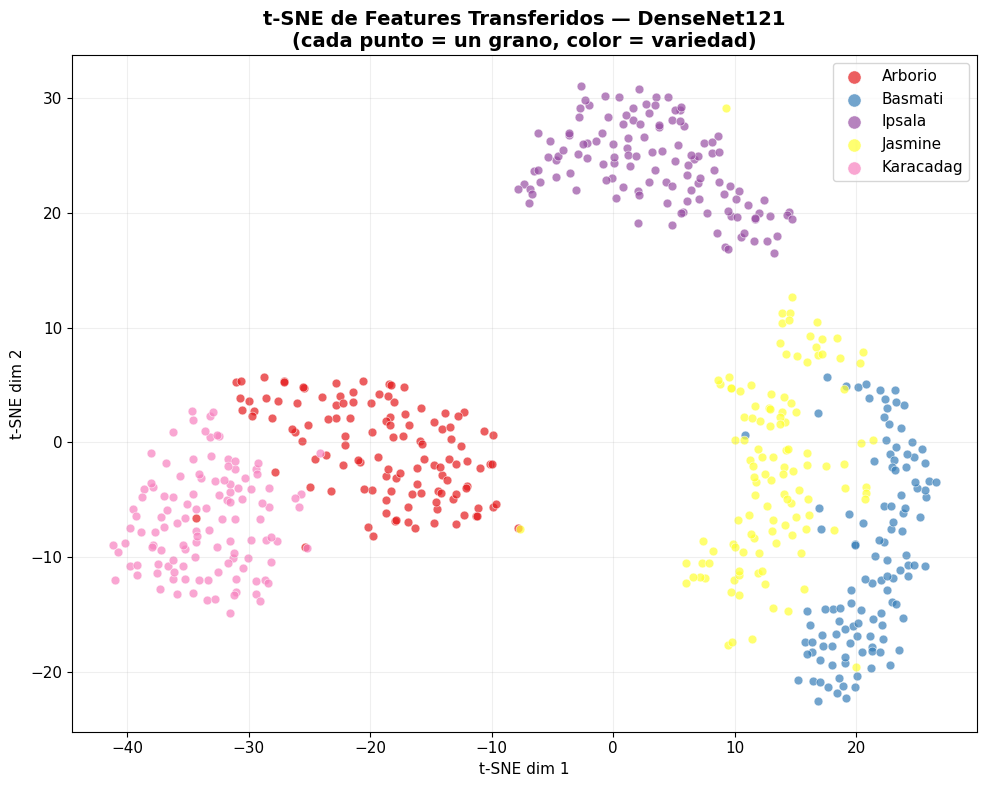


💡 Variedades con clusters separados → el backbone distingue bien sus features
💡 Variedades cuyos clusters se superponen → son visualmente similares (confusiones esperadas)


In [45]:
print("🔄 Calculando t-SNE (esto toma ~30 segundos)...")
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
features_2d = tsne.fit_transform(features)

fig, ax = plt.subplots(figsize=(10, 8))
scatter_colors = plt.cm.Set1(np.linspace(0, 0.8, NUM_CLASSES_2))

for class_idx in range(NUM_CLASSES_2):
    mask = labels == class_idx
    ax.scatter(features_2d[mask, 0], features_2d[mask, 1],
               c=[scatter_colors[class_idx]], label=CLASS_NAMES_2[class_idx],
               alpha=0.7, s=40, edgecolors='white', linewidths=0.5)

ax.set_title(f't-SNE de Features Transferidos — {best_name}\n'
             f'(cada punto = un grano, color = variedad)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, markerscale=1.5, loc='best')
ax.set_xlabel('t-SNE dim 1'); ax.set_ylabel('t-SNE dim 2')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print("\n💡 Variedades con clusters separados → el backbone distingue bien sus features")
print("💡 Variedades cuyos clusters se superponen → son visualmente similares (confusiones esperadas)")

### 3.4. Comparación t-SNE: Features aleatorios vs. Features transferidos

In [47]:
# Misma arquitectura que el mejor backbone, pero con pesos ALEATORIOS (sin Transfer Learning)
base_random = best['backbone_fn'](weights=None, include_top=False, input_shape=(224, 224, 3))
gap = layers.GlobalAveragePooling2D()

random_features, random_labels, count = [], [], 0
for imgs, lbls in val_best:
    feats = gap(base_random(imgs, training=False)).numpy()
    random_features.append(feats)
    random_labels.append(np.argmax(lbls.numpy(), axis=1))
    count += imgs.shape[0]
    if count >= 600:
        break

random_features = np.concatenate(random_features)[:600]
random_labels_arr = np.concatenate(random_labels)[:600]

tsne_random = TSNE(n_components=2, random_state=SEED, perplexity=30)
random_2d = tsne_random.fit_transform(random_features)

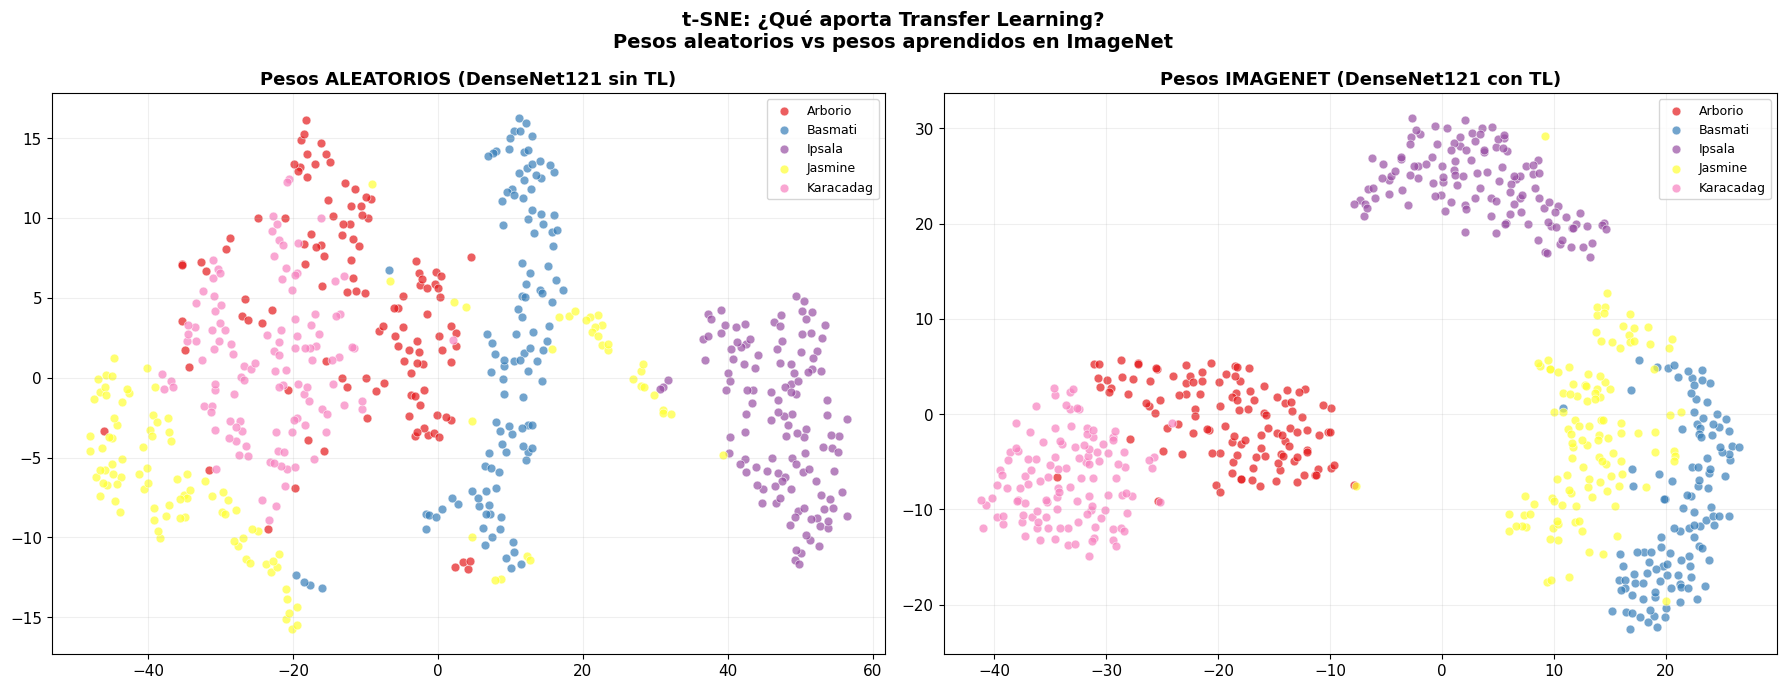

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, data, lab, title_str in [
    (axes[0], random_2d, random_labels_arr, f'Pesos ALEATORIOS ({best_name} sin TL)'),
    (axes[1], features_2d, labels, f'Pesos IMAGENET ({best_name} con TL)')
]:
    for class_idx in range(NUM_CLASSES_2):
        mask = lab == class_idx
        ax.scatter(data[mask, 0], data[mask, 1],
                   c=[scatter_colors[class_idx]], label=CLASS_NAMES_2[class_idx],
                   alpha=0.7, s=40, edgecolors='white', linewidths=0.5)
    ax.set_title(title_str, fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.2)

plt.suptitle('t-SNE: ¿Qué aporta Transfer Learning?\n'
             'Pesos aleatorios vs pesos aprendidos en ImageNet',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> 📝 **Nota:** los granos de arroz sobre fondo negro son imágenes muy "limpias", así que incluso features aleatorios pueden separar algo las clases (por tamaño y forma). Compara **qué tan compactos y separados** quedan los clusters en cada caso.

### ✅ Conclusión Ejemplo 3 (completar con tus resultados)

**Hallazgos del benchmark:**
1. ¿Qué backbone obtuvo mayor test accuracy? ¿La diferencia justifica su costo en tiempo y parámetros?
2. ¿Cuál es el más rápido? ¿Sería viable en una cámara o dispositivo embebido de una planta arrocera?
3. ¿Qué variedades se superponen en el t-SNE? ¿Coincide con la matriz de confusión del Ejemplo 2?

---
# 📋 Resumen

| Concepto | Cómo lo aplicamos |
|----------|-------------|
| **Transfer Learning** | Reutilizar conocimiento de ImageNet en imágenes satelitales y de granos de arroz |
| **Feature Extraction** | Congelar el backbone y entrenar solo el clasificador nuevo |
| **`include_top=False`** | Remover las capas Dense originales de 1000 clases |
| **`trainable = False`** | Congelar todos los pesos del backbone |
| **`preprocess_input`** | Cada backbone usa **su propia** normalización (clave en el benchmark) |
| **`training=False`** | Las capas BN usan las estadísticas de ImageNet |
| **Binaria desbalanceada** | Sigmoide + `binary_crossentropy` + `class_weight` + Precision/Recall/AUC |
| **Clasificador → detector** | Ventana deslizante sobre una escena satelital completa |
| **Multiclase** | Softmax + `categorical_crossentropy` + matriz de confusión |
| **t-SNE** | Visualización de features de alta dimensión en 2D |

## Próximo paso: Fine-Tuning

En Feature Extraction tratamos el backbone como caja negra. Con **Fine-Tuning** descongelaremos las últimas capas y las re-entrenaremos con un learning rate bajo para **adaptar** los features a vistas satelitales y granos de arroz, lo que debería subir el rendimiento, sobre todo en los barcos, cuyo dominio es más lejano a ImageNet.

---
*IS056B — Ingeniería del Conocimiento | UNCP 2026-II*